# Building a Multi Layer Perceptron for Diabetes Risk Prediction

Welcome to your Deep Learning project! In this notebook, you’ll take on the role of a data scientist building a neural network that predicts diabetes risk, helping healthcare providers prioritize patients for diagnostic testing.

### What you'll build

By completing this notebook, you will _(demonstrate ability to)_:

- Design MLP architectures with appropriate depth, width, and activations
- Preprocess data with proper splitting, normalization, and batching
- Implement training loops with forward/backward passes and optimization
- Apply evaluation metrics suited for specialized applications
- Diagnose overfitting/underfitting using loss curves
- Improve models systematically through hyperparameter tuning and regularization
- Interpret performance in context with actionable recommendations

**Dataset**: [CDC Diabetes Health Indicators](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) (balanced subset of 50,000 patients, 21 features)  
**Estimated time**: 5-6 hours  

> *Have more questions about the project?* Review the [README.md](../README.md) for full project context, setup instructions, and deliverables.

### Ready to get started?

This notebook is divided into 8 sections: 

```Setup → Data Loading → Data Preprocessing → Model Design → Model Training → Model Evaluation → Model Improvements → Conclusion```

Follow them in sequence to complete your project!

---
## Step 0: Set up the environment

Let's begin by importing the necessary libraries and setting up our environment for reproducibility.

In [88]:
# Standard library imports
import numpy as np
import pandas as pd
import numbers
import matplotlib.pyplot as plt
from typing import Dict, Tuple, List, Optional

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Scikit-learn imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')

print("All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")

All libraries imported successfully!
PyTorch version: 2.8.0+cu128


In [6]:
# Set random seeds for reproducibility
# This ensures that your results are consistent across runs
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
    
print(f"Random seed set to {RANDOM_SEED}")

Random seed set to 42


> **Why reproducibility matters**: Setting random seeds ensures that your results are consistent across different runs. This is critical for debugging and comparing different model configurations. 
> <br>In production systems, reproducibility helps with model versioning and validation.

In [89]:
# Use GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    # Set cuDNN to deterministic mode for reproducibility
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

Using device: cpu


> **Moving execution to device**: Transferring your model and tensors to the GPU can drastically improve performance.  
> <br>Use `.to(device)` for models and tensors to ensure everything runs on the same hardware.  
> <br>*Example:*  
> ```model = model.to(device)```   
> ```inputs = inputs.to(device)```  
> <br>**Note**: Mixing CPU and GPU tensors in operations will raise errors.

---
## Step 1: Load and explore the dataset

Understanding your data is the first critical step in any deep learning project. In this step, you will load the dataset and perform exploratory data analysis to understand your dataset.

The CDC diabetes dataset is provided as a CSV file in the [`data/`](../data/) directory. You'll use [pandas](https://pandas.pydata.org/) to load it into a DataFrame for analysis.

### 1.1 Load the dataset

The dataset contains health indicators from the CDC's Behavioral Risk Factor Surveillance System. Each row represents a patient with 21 health-related features and a binary diabetes diagnosis.

In [90]:
# Load the diabetes dataset
import os
def load_data(path):
    """Load the CSV at `path` into a DataFrame. Raises FileNotFoundError if it does not exist."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"Dataset not found at: {path}")
    return pd.read_csv(path)

df = load_data('data/diabetes_data.csv')
print(f"Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print(f"\nFirst few rows:")
df.head()

Dataset loaded successfully!
Dataset shape: (50000, 22)

First few rows:


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,27,1,0,0,1,0,1,...,0,2,0,0,0,1,12,6,8,1
1,0,0,1,30,0,0,0,1,1,1,...,0,1,0,0,0,1,8,5,5,0
2,1,0,1,33,0,0,0,1,1,1,...,0,3,0,0,0,0,7,5,6,0
3,1,1,1,25,0,0,0,1,1,1,...,0,1,0,0,0,1,9,6,4,0
4,1,1,1,29,1,0,1,0,0,1,...,0,5,3,10,1,0,9,4,2,1


### Shape, data types and missing values

In [91]:
# Display basic dataset information

print(f"Shape: {df.shape}")
df.info()

Shape: (50000, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   HighBP                50000 non-null  int64
 1   HighChol              50000 non-null  int64
 2   CholCheck             50000 non-null  int64
 3   BMI                   50000 non-null  int64
 4   Smoker                50000 non-null  int64
 5   Stroke                50000 non-null  int64
 6   HeartDiseaseorAttack  50000 non-null  int64
 7   PhysActivity          50000 non-null  int64
 8   Fruits                50000 non-null  int64
 9   Veggies               50000 non-null  int64
 10  HvyAlcoholConsump     50000 non-null  int64
 11  AnyHealthcare         50000 non-null  int64
 12  NoDocbcCost           50000 non-null  int64
 13  GenHlth               50000 non-null  int64
 14  MentHlth              50000 non-null  int64
 15  PhysHlth              50000 non-nu

### 1.2 Understanding the features

The dataset contains 21 health and lifestyle indicators. Let's examine what each feature represents and its clinical significance:

| Feature | Description | Type | Clinical Significance |
|---------|-------------|------|----------------------|
| **Diabetes_binary** | Diabetes diagnosis | Binary (0/1) | **Target variable** |
| HighBP | High blood pressure diagnosis | Binary | Strong risk factor |
| HighChol | High cholesterol diagnosis | Binary | Cardiovascular risk |
| CholCheck | Cholesterol check in past 5 years | Binary | Preventive care indicator |
| BMI | Body Mass Index | Continuous | Key obesity indicator |
| Smoker | Smoking history | Binary | Lifestyle risk factor |
| Stroke | History of stroke | Binary | Cardiovascular complication |
| HeartDiseaseorAttack | Coronary heart disease or MI | Binary | Cardiovascular complication |
| PhysActivity | Physical activity in past 30 days | Binary | Protective factor |
| Fruits | Fruit consumption (1+ per day) | Binary | Dietary indicator |
| Veggies | Vegetable consumption (1+ per day) | Binary | Dietary indicator |
| HvyAlcoholConsump | Heavy alcohol consumption | Binary | Lifestyle risk factor |
| AnyHealthcare | Any healthcare coverage | Binary | Access to care |
| NoDocbcCost | Could not see doctor due to cost | Binary | Healthcare barrier |
| GenHlth | General health (1-5 scale) | Ordinal | Self-reported health status |
| MentHlth | Mental health (days not good in past 30) | Continuous | Mental health indicator |
| PhysHlth | Physical health (days not good in past 30) | Continuous | Physical health indicator |
| DiffWalk | Difficulty walking or climbing stairs | Binary | Mobility indicator |
| Sex | Biological sex | Binary | Demographic factor |
| Age | Age category (1-13) | Ordinal | Strong demographic predictor |
| Education | Education level (1-6) | Ordinal | Socioeconomic indicator |
| Income | Income level (1-8) | Ordinal | Socioeconomic indicator |

For a complete overview of the dataset, refer to the [`data/data_dictionary.md`](data/data_dictionary.md) file.

> **Feature dictionaries in the real-world**: In practice, you'll often create these yourself by interviewing domain experts. Always document: feature meaning, type, measurement method, and known limitations.
> <br> Think of the feature dictionary as your model's "instruction manual"; without it, even brilliant ML work becomes unusable in production.


### 1.3 Perform exploratory data analysis (EDA)

Understanding your data involves checking for missing values, reviewing feature distributions, understanding target variable distribution, and identifying patterns that will inform your modeling decisions.

In [92]:
# Check for missing values in the dataset

missing_values = df.isnull().sum()
print(f"Total missing values: {missing_values.sum()}")
print("Missing values per column:")
print(missing_values)
print(f"\nTotal missing values: {missing_values.sum()}")

Total missing values: 0
Missing values per column:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64

Total missing values: 0


> **Handling missing values** Even though this dataset has no missing values, it's crucial to check for them in any data workflow since they can disrupt model training, bias results, or break computations. Common strategies to handle missing values include:
>   - *Removal:* Drop rows or columns if the proportion of missing data is small.  
>   - *Imputation:* Fill with mean, median, mode, or domain-specific defaults.  
>   - *Model-based methods:* Predict missing values using other features.  
> Always make sure to also analyze *why* data is missing: it can reveal data collection issues or hidden patterns!  
>
> *Reference:* [ Working with missing data in Pandas](https://pandas.pydata.org/docs/user_guide/missing_data.html)


### Target Distribution

Target Variable Distribution:
No Diabetes (0): 25,000 (50.00%)
Diabetes (1): 25,000 (50.00%)


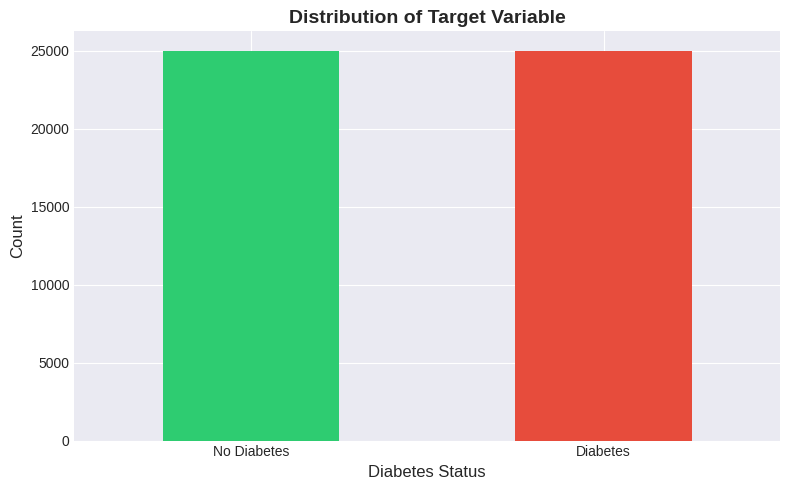

In [93]:
# Analyze and visualize the target variable distribution

target_distribution = df['Diabetes_binary'].value_counts().sort_index()
target_percentage = df['Diabetes_binary'].value_counts(normalize=True).sort_index() * 100

print("Target Variable Distribution:")
print(f"No Diabetes (0): {target_distribution[0]:,} ({target_percentage[0]:.2f}%)")
print(f"Diabetes (1): {target_distribution[1]:,} ({target_percentage[1]:.2f}%)")

# Visualize the distribution
fig, ax = plt.subplots(figsize=(8, 5))
target_distribution.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'])
ax.set_xlabel('Diabetes Status', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Distribution of Target Variable', fontsize=14, fontweight='bold')
ax.set_xticklabels(['No Diabetes', 'Diabetes'], rotation=0)
plt.tight_layout()
plt.show()

> **Understanding the balanced dataset:** You have noticed this dataset has a 50-50 split between diabetic and non-diabetic patients. The original CDC data actually has ~14% diabetes prevalence, reflecting real population statistics.
>
> Why did we balance it?
> - *Simplifies learning:* Lets you focus on neural network fundamentals without juggling class imbalance complexity
> - *Valid strategy:* Downsampling the majority class is common in production when you have enough minority samples (we have 7,000+ diabetic cases!)
> - *Practical benefits:* Simpler code, faster training, often performs just as well
>
> Alternatives to deal with class imbalance involve upsampling and/or cost-sensitive learning.
>
> *Production note:* You'd typically train on balanced data but evaluate on the real distribution. Here we use balanced for both to keep things simple, but remember to test on realistic proportions before deployment!

### Statistical Summary

In [94]:
# Examine basic statistical properties of the dataset
# HINT: Statistical summaries (mean, std, min, max, quartiles) help you understand feature 
#       distributions and identify potential outliers. DataFrames have built-in methods that 
#       compute these statistics across all numerical columns at once.
# REFERENCE: https://pandas.pydata.org/docs/reference/frame.html
# Pay attention to the ranges of different features since this informs normalization needs

df.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,50000.0,0.56118,0.496248,0.0,0.0,1.0,1.0,1.0
HighChol,50000.0,0.52728,0.499260,0.0,0.0,1.0,1.0,1.0
CholCheck,50000.0,0.97578,0.153733,0.0,1.0,1.0,1.0,1.0
BMI,50000.0,29.86934,7.183087,12.0,25.0,29.0,33.0,98.0
Smoker,50000.0,0.47422,0.499340,0.0,0.0,0.0,1.0,1.0
Stroke,50000.0,0.06210,0.241340,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,50000.0,0.15030,0.357369,0.0,0.0,0.0,0.0,1.0
PhysActivity,50000.0,0.70372,0.456621,0.0,0.0,1.0,1.0,1.0
Fruits,50000.0,0.61260,0.487161,0.0,0.0,1.0,1.0,1.0
Veggies,50000.0,0.78616,0.410019,0.0,1.0,1.0,1.0,1.0


> **Understanding statistical summaries** Statistical summaries provide a quick snapshot of your dataset’s structure and variability.  
>
> - *Central tendency:* Metrics like mean and median reveal typical values but can be distorted by skewed data or outliers.  
> - *Spread:* Standard deviation and quartiles highlight how dispersed the data is, where wide spreads may indicate inconsistent scales or high variability.  
> - *Range and extremes:* Min/max values help spot potential data entry errors or outliers needing review.  
> - *Feature type awareness:*  
>   - Continuous features benefit from scale checks and normalization.  
>   - Ordinal or categorical features should be interpreted by the distribution of categories, not numeric statistics.  
>
> *Why this matters:* Understanding the shape, spread, and nature of your data guides preprocessing decisions like scaling, encoding, and handling outliers for reliable modeling.


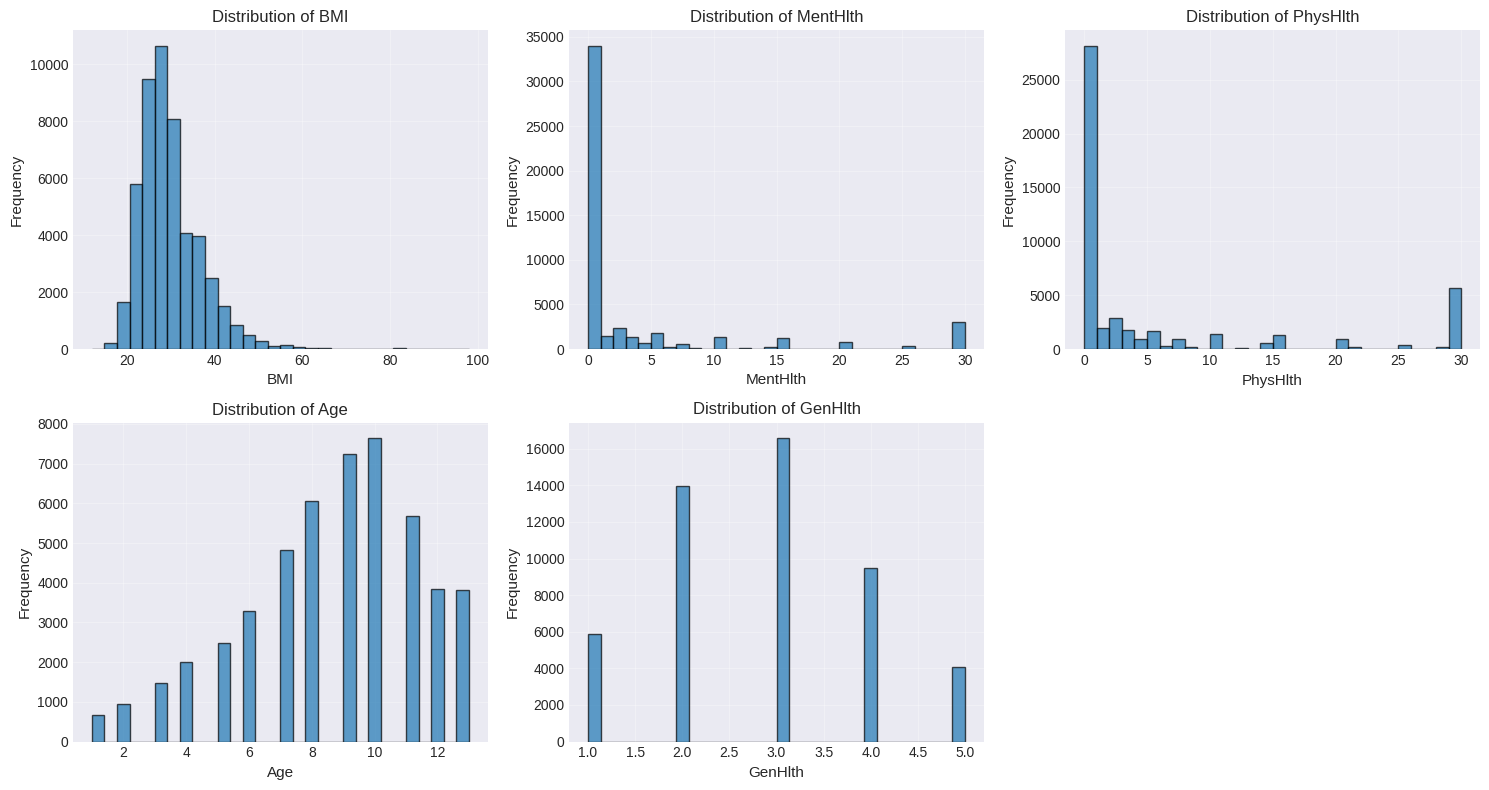

In [95]:
# Visualize distributions of key continuous features
continuous_features = ['BMI', 'MentHlth', 'PhysHlth', 'Age', 'GenHlth']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for idx, feature in enumerate(continuous_features):
    axes[idx].hist(df[feature], bins=30, edgecolor='black', alpha=0.7)
    axes[idx].set_xlabel(feature, fontsize=11)
    axes[idx].set_ylabel('Frequency', fontsize=11)
    axes[idx].set_title(f'Distribution of {feature}', fontsize=12)
    axes[idx].grid(True, alpha=0.3)

# Remove extra subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

> **Interpreting the distribution plots** These histograms reveal how each continuous feature is distributed:  
> - *Shape:* Skewed or symmetric distributions indicate how values are spread.  
> - *Spread:* Wide distributions suggest high variability; scaling will be needed.  
> - *Peaks:* Multiple peaks can hint at subgroups or hidden patterns in the data.  
> - *Outliers:* Extreme values can distort model learning; worth investigating.  
> - *Continuity:* Features with few distinct values might behave more like categories.

### Duplicate Rows

In [96]:
feature_cols = [c for c in df.columns if c != 'Diabetes_binary']

repeat_copies = df.duplicated().sum()                      # rows identical to an earlier row
rows_in_dup_groups = df.duplicated(keep=False).sum()       # includes the first occurrence
conflicting_groups = (df.groupby(feature_cols)['Diabetes_binary'].nunique() > 1).sum()

print(f"Repeat copies (first occurrence kept): {repeat_copies}")
print(f"Rows belonging to a duplicate group: {rows_in_dup_groups}")
print(f"Feature-identical groups with conflicting labels: {conflicting_groups}")
print("\nLabels of rows in duplicate groups:")
print(df[df.duplicated(keep=False)]['Diabetes_binary'].value_counts())

Repeat copies (first occurrence kept): 938
Rows belonging to a duplicate group: 1609
Feature-identical groups with conflicting labels: 222

Labels of rows in duplicate groups:
Diabetes_binary
0    1370
1     239
Name: count, dtype: int64


### Correlation with the target

Diabetes_binary         1.000000
GenHlth                 0.406625
HighBP                  0.384610
HighChol                0.283302
BMI                     0.282141
Age                     0.280998
DiffWalk                0.270842
PhysHlth                0.215880
HeartDiseaseorAttack    0.208582
Stroke                  0.127208
CholCheck               0.113575
MentHlth                0.096566
Smoker                  0.085354
Sex                     0.047573
NoDocbcCost             0.037306
AnyHealthcare           0.027282
Fruits                 -0.057641
Veggies                -0.069071
HvyAlcoholConsump      -0.099634
PhysActivity           -0.160485
Education              -0.169717
Income                 -0.226207
Name: Diabetes_binary, dtype: float64
Feature Correlations with Diabetes:
Diabetes_binary         1.000000
GenHlth                 0.406625
HighBP                  0.384610
HighChol                0.283302
BMI                     0.282141
Age                     0.280998
Di

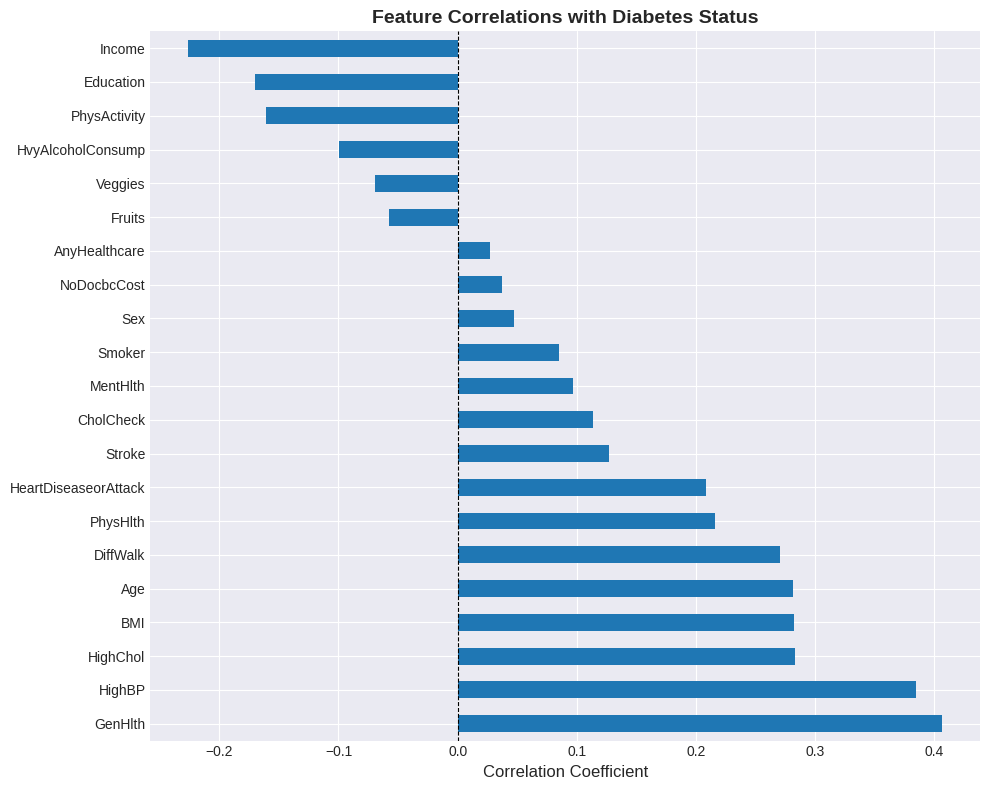

In [97]:
# Analyze correlation between features and the target variable
# HINT: Correlation coefficients measure linear relationships between variables (-1 to +1).
#       You need to compute pairwise correlations between all features, then focus on 
#       correlations between each feature and your target variable. DataFrames can compute 
#       correlation matrices, and you can select specific columns from the result.
# REFERENCE: https://pandas.pydata.org/docs/reference/frame.html
# Strong correlations indicate features that may be predictive of diabetes

# Compute correlation with target
correlations = df.corr()['Diabetes_binary'].sort_values(ascending=False)
print(correlations)

print("Feature Correlations with Diabetes:")
print(correlations)

# Visualize top correlations
fig, ax = plt.subplots(figsize=(10, 8))
correlations[1:].plot(kind='barh', ax=ax)  # Exclude self-correlation
ax.set_xlabel('Correlation Coefficient', fontsize=12)
ax.set_title('Feature Correlations with Diabetes Status', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

> **Understanding correlations** Correlations show how features move together, not cause and effect.  
> - *Positive* → variables increase together; *Negative* → one rises as the other falls.  
> - Strong values (±1) imply tighter linear links; near 0 means weak or no linear relation.  
> - Watch for *multicollinearity* and remember that *nonlinear patterns* won’t appear here.  
>  
> *IMPORTANT*: Use correlations to spot patterns, not to draw conclusions.

## 1.4 Observations

- **Shape and types:** 50,000 rows x 22 columns (21 features + `Diabetes_binary`); every column is `int64`, so no type conversion or categorical encoding is needed.
- **No missing values:** `isnull().sum()` is 0 for every column, so no imputation or row removal is needed.
- **Perfectly balanced target:** 25,000 negative and 25,000 positive (50/50). Accuracy is a fair metric here, but recall still matters most clinically because a false negative is a missed case.
- **Very different feature scales:** `BMI` ranges 12-98, `MentHlth`/`PhysHlth` 0-30, `Age` 1-13, `Income` 1-8, and the binary features 0-1. Features must be scaled (e.g. `StandardScaler`, fit on the training set only) before training.
- **Strongest positive correlations with diabetes:** `GenHlth` (0.41), `HighBP` (0.38), `HighChol` (0.28), `BMI` (0.28), `Age` (0.28), `DiffWalk` (0.27).
- **Protective factors (negative correlations):** `Income` (-0.23), `Education` (-0.17), `PhysActivity` (-0.16), `HvyAlcoholConsump` (-0.10). Income and education are socioeconomic proxies, so fairness across groups should be considered.
- **Weak individual features:** `Sex`, `NoDocbcCost` and `AnyHealthcare` have |r| < 0.05; they may add little on their own.
- **Outliers:** `BMI` reaches 98 (mean about 29.9, std about 7.2), and `MentHlth`/`PhysHlth` are heavily skewed toward 0 with a spike at 30.
- **Duplicate rows:** 938 rows are exact duplicates. Decide whether to drop them before splitting so copies do not leak across train and test.
- **Multicollinearity:** `HighBP`, `HighChol` and `BMI` correlate with each other, as do `MentHlth` and `PhysHlth`.

<details open>
  <summary><h4>Checkpoint – Understanding the dataset</h4></summary>
  
  Before proceeding to preprocessing, ensure you understand:

  - [ ] The target variable distribution and its implications for evaluation
  - [ ] Which features show strong correlations with diabetes
  - [ ] The need for feature scaling due to different value ranges
  - [ ] The absence of missing values (simplifies preprocessing)

</details>

---
## Step 2: Preprocess the dataset

Proper data preprocessing is essential for neural network training. Raw data often needs to be split, normalized, and batched before it can be used effectively. This section transforms your dataset into a format optimized for PyTorch models.

### 2.1 Separate features and target

Machine learning models require splitting your data into input features (X) and target labels (y). The features are what the model uses to make predictions, while the target is what you're trying to predict. 

In [98]:
TARGET = 'Diabetes_binary'
BATCH_SIZE = 64

In [99]:
# Separate features (X) and target variable (y)

X = df.drop(columns=[TARGET])
y = df[TARGET]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nFeature columns: {list(X.columns)}")

Features shape: (50000, 21)
Target shape: (50000,)

Feature columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


### 2.2 Create train/validation/test splits

Following best practices, you'll split the data into three sets:

- Training set (60%): Used to train the model (learn patterns, update weights)
- Validation set (20%): Used during development to tune hyperparameters and monitor overfitting
- Test set (20%): Final evaluation on completely unseen data (simulates real-world deployment)

This is a best practice because separating validation from testing ensures that model tuning doesn’t “leak” information from your final evaluation, leading to more trustworthy results.

In [100]:

df_copy = df.copy()
def preprocess_data(dataframe, drop_duplicates=True):
    """Drop exact duplicate rows, split into features/target, then into stratified 60/20/20 train/val/test.

    Returns (X_train, X_test, X_val, y_train, y_test, y_val). Raises ValueError if the DataFrame is empty.
    """
    if dataframe.empty:
        raise ValueError("DataFrame is empty")
    if drop_duplicates:
        dataframe = dataframe.drop_duplicates()

    X = dataframe.drop(columns=[TARGET])
    y = dataframe[TARGET]

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.4, stratify=y, random_state=RANDOM_SEED)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_SEED)

    return X_train, X_test, X_val, y_train, y_test, y_val

X_train, X_test, X_val, y_train, y_test, y_val = preprocess_data(df_copy)

In [101]:
# Verify split sizes and class distributions
print("Split Sizes:")
print(f"Training set: {X_train.shape[0]:,} samples ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Validation set: {X_val.shape[0]:,} samples ({X_val.shape[0]/len(df)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]:,} samples ({X_test.shape[0]/len(df)*100:.1f}%)")

print("\nClass Distribution:")
print(f"Training - Diabetes prevalence: {y_train.mean()*100:.2f}%")
print(f"Validation - Diabetes prevalence: {y_val.mean()*100:.2f}%")
print(f"Test - Diabetes prevalence: {y_test.mean()*100:.2f}%")

Split Sizes:
Training set: 29,437 samples (58.9%)
Validation set: 9,812 samples (19.6%)
Test set: 9,813 samples (19.6%)

Class Distribution:
Training - Diabetes prevalence: 50.70%
Validation - Diabetes prevalence: 50.70%
Test - Diabetes prevalence: 50.71%


In [20]:
total = len(X_train) + len(X_val) + len(X_test)
for name, y_split in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(f"{name:5s}: {len(y_split):6d} rows ({len(y_split) / total:.1%}), positive rate {y_split.mean():.2%}")
print(f"full (deduplicated) positive rate: {pd.concat([y_train, y_val, y_test]).mean():.2%}")

train:  29437 rows (60.0%), positive rate 50.70%
val  :   9812 rows (20.0%), positive rate 50.70%
test :   9813 rows (20.0%), positive rate 50.71%
full (deduplicated) positive rate: 50.70%


<details open>
  <summary><h4>Checkpoint – Validate the data splits</h4></summary>
  
  Before continuing, make sure your dataset splits meet the expected proportions:

  - [ ] Training set contains approximately 60% of the data
  - [ ] Validation and test sets each contain approximately 20% of the data
  - [ ] Class presence is as expected (same ratio as for the full dataset) in all three splits

  If they aren’t, revisit your splitting logic before moving forward.

</details>

### 2.3 Normalize features

Neural networks perform better when input features are on similar scales. Standardization transforms features to have zero mean and unit variance, which helps gradients flow properly during training and speeds up convergence.

In [102]:
# Normalize features with a scaler, and populate the empty variables below with the scaled feature sets

def scale_features(X_train, X_val, X_test):
    """Fit StandardScaler on the training features only; transform train, val and test."""
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled, X_val_scaled, X_test_scaled

X_train_scaled, X_val_scaled, X_test_scaled = scale_features(X_train, X_val, X_test)

> **Don't forget the golden rule!** Only fit the scaler on training data to prevent data leakage, then use that fitted scaler to transform all three splits.   
> If you fit the scaler on validation or test data, their statistics (mean, standard deviation) would influence the training process. This is called *data leakage*, and leads to overly optimistic performance estimates. 
> <br><br>Think of it this way: In real deployment, you only have access to training data when building your model. The test set represents future, unseen entries that you should not have visibility on!

### 2.4 Convert to PyTorch tensors

PyTorch requires data to be in tensor format and batched for efficient GPU processing. DataLoaders handle batching, shuffling, and parallel data loading automatically.

In [103]:
# Convert scaled NumPy arrays to PyTorch tensors by populating the missing variables below
# Note: Features should be floating-point tensors for 
#       neural network computations, while binary classification targets work with long tensors.
#       PyTorch provides tensor creation functions for different data types.
# REFERENCE: https://pytorch.org/docs/stable/torch.html#tensors
# Why different tensor types? Cross-entropy loss expects Long (integer) labels for class indices

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.long)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.long)

print("Conversion to PyTorch tensors completed!")
print(f"\nTraining features: {X_train_tensor.shape}, dtype: {X_train_tensor.dtype}")
print(f"Training labels: {y_train_tensor.shape}, dtype: {y_train_tensor.dtype}")

Conversion to PyTorch tensors completed!

Training features: torch.Size([29437, 21]), dtype: torch.float32
Training labels: torch.Size([29437]), dtype: torch.int64


> **Why convert to tensors?** Neural networks run on *tensors*, not NumPy arrays, because tensors can live on the GPU and support automatic differentiation.  
> Converting ensures your data can be used efficiently during training and lets PyTorch handle gradients and fast parallel math.  
>  
> *IMPORTANT*: Avoid switching back and forth between NumPy and tensors: each conversion moves data between memory spaces and slows things down.  

In [104]:
# Create DataLoaders for train, validation, and test sets
# Note: PyTorch provides utilities in torch.utils.data to wrap tensors into datasets and create batching iterators.
#       (1) combine feature and label tensors into dataset objects, and 
#       (2) wrap datasets in loaders with appropriate batch sizes. Training data should be 
#       shuffled, but validation/test should not.
# REFERENCE: https://pytorch.org/tutorials/beginner/basics/data_tutorial.html

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_tensor, y_val_tensor), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=BATCH_SIZE, shuffle=False)

print(f"Number of batches:")
print(f"Training: {len(train_loader)} batches")
print(f"Validation: {len(val_loader)} batches")
print(f"Test: {len(test_loader)} batches")

Number of batches:
Training: 460 batches
Validation: 154 batches
Test: 154 batches


In [105]:
# Verify DataLoader setup by examining one batch
for X_batch, y_batch in train_loader:
    print("Sample batch from training DataLoader:")
    print(f"Features shape: {X_batch.shape}")
    print(f"Labels shape: {y_batch.shape}")
    print(f"\nFeature sample (first 5 values): {X_batch[0, :5]}")
    print(f"Label sample (first 10): {y_batch[:10]}")
    break  # Only examine first batch

Sample batch from training DataLoader:
Features shape: torch.Size([64, 21])
Labels shape: torch.Size([64])

Feature sample (first 5 values): tensor([ 0.8706,  0.9364,  0.1597, -0.2712, -0.9608])
Label sample (first 10): tensor([1, 1, 1, 1, 1, 1, 0, 0, 0, 0])


> **Batch processing efficiency**: DataLoaders enable efficient mini-batch gradient descent by automatically batching your data. This allows for more stable gradient estimates than single-sample updates (SGD) while being more memory-efficient than using the entire dataset at once (batch gradient descent). Shuffling the training data each epoch prevents the model from learning the order of examples.

<details open>
  <summary><h4>Checkpoint – Validate the dataLoader output</h4></summary>
  
  Before training, confirm that your batches are correctly structured and preprocessed:
  
  - [ ] **Feature batch shape:** `(64, 21)` → 64 samples × 21 features  
  - [ ] **Label batch shape:** `(64,)` → 64 labels  
  - [ ] **Feature values:** normalized 
  - [ ] **Labels:** binary values (**0 or 1**)  
  
  If any shapes or values look off, revisit your preprocessing or batching steps before proceeding.
</details>

---
## Step 3: Design the model architecture

Now it's time to design your neural network! You'll build a multi-layer perceptron (MLP): a feed-forward neural network that learns from health indicators to predict diabetes risk. The goal is to define an architecture that balances **expressiveness** (ability to learn complex patterns) and **efficiency** (training speed and generalization).


### 3.1 Design considerations

Before implementing the model, consider these architectural decisions:

**Input Layer**:
- Size: Must match the number of features in the dataset (21 for our diabetes data)

**Hidden Layers**:
- **Depth**: Deeper networks can capture more complex patterns but increase the risk of overfitting and slow down training
- **Width**: Choose enough neurons to represent useful feature interactions without overcomplicating the model  
- **Activation**: Non-linear activations (like ReLU) allow the model to learn complex relationships beyond simple linear boundaries  

**Output Layer**:
- Size: Single neuron for binary classification (outputs probability of diabetes)
- Activation: Sigmoid function squashes output to range [0, 1], representing probability

### 3.2 Implement the neural network

You'll create a Multi-Layer Perceptron (MLP) using PyTorch's `nn.Module` class. This approach lets you define each layer and the forward pass explicitly, giving you full control over your model’s behavior.

In [106]:
# Define your DiabetesClassifier neural network class

class DiabetesClassifier(nn.Module):
    def __init__(self, input_size, hidden_sizes=(BATCH_SIZE, 32)):
        super().__init__()
        h1, h2 = hidden_sizes
        self.network = nn.Sequential(
            nn.Linear(input_size, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.network(x)

### 3.3 Instantiate and inspect the model

Once the architecture is defined, create an instance of your model and inspect its structure. Understanding your model's parameters and layers helps ensure it's built as intended and gives you insight into its complexity.

In [107]:
#  Create an instance of your model, and set it to run on your device

from torchinfo import summary

num_features = X_train_tensor.shape[1]
model = DiabetesClassifier(num_features).to(device)

summary(model, input_size=(BATCH_SIZE, num_features), device=device)

print("Model Architecture:")
print(model)
print("\n" + "="*50)

Model Architecture:
DiabetesClassifier(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
    (5): Sigmoid()
  )
)



In [2]:
%pip install torchinfo


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [108]:
# Count total parameters in the model
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Display parameter breakdown by layer
print("\nParameter breakdown:")
for name, param in model.named_parameters():
    print(f"{name:20s} - Shape: {str(param.shape):20s} - Parameters: {param.numel():,}")

Total parameters: 3,521
Trainable parameters: 3,521

Parameter breakdown:
network.0.weight     - Shape: torch.Size([64, 21]) - Parameters: 1,344
network.0.bias       - Shape: torch.Size([64])     - Parameters: 64
network.2.weight     - Shape: torch.Size([32, 64]) - Parameters: 2,048
network.2.bias       - Shape: torch.Size([32])     - Parameters: 32
network.4.weight     - Shape: torch.Size([1, 32])  - Parameters: 32
network.4.bias       - Shape: torch.Size([1])      - Parameters: 1


> **Understanding model inspection** Inspecting your model helps confirm that the architecture matches your design intent, both in structure and in parameter count.  
>  
> - *Check layer flow:* Verify inputs and outputs connect as expected, especially when stacking layers or combining modules.  
> - *Parameter awareness:* Knowing where parameters concentrate helps spot over- or under-parameterized designs early.  
> - *Debugging aid:* If training behaves unexpectedly, inspection can reveal mismatched layer sizes, missing activations, or frozen parameters.  
> - *Efficiency check:* Smaller models train faster but may underfit; larger ones capture complexity but risk overfitting.  
>  
> Regular inspection builds intuition about how architectural choices impact learning and performance.


### 3.4 Test the forward pass

Before training, confirm that your model processes input data correctly. This step ensures that tensor shapes are compatible and that the output has the expected dimensions for binary classification.

In [109]:
# Test the forward pass with a sample batch

# Get a sample batch
for X_batch, y_batch in train_loader:
    # Move data to device
    X_batch = X_batch.to(device)

    # Forward pass
    output =  model(X_batch)
    
    print("Forward Pass Test:")
    print(f"Input shape: {X_batch.shape}")
    print(f"Output shape: {output.shape}")
    print(f"\nSample output (first 10):")
    print(output[:10].squeeze().detach().cpu().numpy())
    print(f"\nActual labels (first 10):")
    print(y_batch[:10].numpy())
    
    break  # Only test with first batch

Forward Pass Test:
Input shape: torch.Size([64, 21])
Output shape: torch.Size([64, 1])

Sample output (first 10):
[0.5285977  0.5253534  0.48838156 0.5931276  0.52584046 0.5158077
 0.5504002  0.51822317 0.5250031  0.4902049 ]

Actual labels (first 10):
[1 1 1 1 1 1 0 0 1 0]


> **Interpreting the forward pass test** If the model runs without errors and outputs a tensor with the expected shape, your architecture and data pipeline are aligned.  
> Unexpected shapes, NaNs, or all-identical predictions can signal setup issues worth fixing before training.  
>  
> Passing this check means you’re ready to move on to loss computation and optimization.


<details open>
  <summary><h4>Checkpoint – Verify Model Architecture</h4></summary>
  
  Before training, ensure your model is correctly defined:
  
  - [ ] **Model instantiated** without errors  
  - [ ] **Architecture matches expectations**: Input size = # features, hidden layers = right complexity for task, output = supports binary classification  
  - [ ] **Model moved to correct device** (GPU if available)  
  
  If anything looks incorrect, revisit your model definition before proceeding to training.
</details>

---
## Step 4: Train the model

Training a neural network involves repeatedly cycling through the data, computing predictions, calculating loss, and updating weights through backpropagation. This section implements the complete training loop with proper validation monitoring.

### 4.1  Define loss function and optimizer

The loss function measures how wrong your model's predictions are, while the optimizer determines how to update weights to reduce this error.

For binary classification with probabilistic outputs (values between 0 and 1), which loss function is most appropriate? Which optimizer is commonly recommended as a strong default for neural networks?

In [110]:
# Define loss function and optimizer

model = DiabetesClassifier(num_features).to(device)

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Training configuration:")
print(f"Loss function: {criterion}")
print(f"Optimizer: {optimizer.__class__.__name__}")
print(f"Learning rate: {optimizer.param_groups[0]['lr']}")
print(f"Number of parameter groups: {len(optimizer.param_groups)}")

Training configuration:
Loss function: BCELoss()
Optimizer: Adam
Learning rate: 0.001
Number of parameter groups: 1


> **Defining the training setup for binary classification:** For binary classification, you need a loss that compares predicted probabilities against binary targets.  
> When choosing an optimizer, consider:  
> - How *stable* you want learning to be (adaptive methods help when tuning is tricky).  
> - How much *control* you need over learning rates or momentum.  
>  
> The “best” choice often depends on your data size, feature scale, and how smoothly the model learns; experiment and observe training behavior.


### 4.2 Implement the training loop

The training loop orchestrates the entire learning process: forward pass, loss computation, backward pass, and weight updates. Validation during training helps detect overfitting early.

In [111]:
def train_model(model: nn.Module,
                train_loader: DataLoader,
                val_loader: DataLoader,
                criterion: nn.Module,
                optimizer: optim.Optimizer,
                device: torch.device,
                num_epochs: int = 50,
                print_every: int = 10) -> Tuple[int, List[float], List[float]]:
    """
    Train a PyTorch model with validation monitoring.
    
    Args:
        model: PyTorch model to train
        train_loader: DataLoader for training data
        val_loader: DataLoader for validation data
        criterion: Loss function
        optimizer: Optimizer
        device: Device to train on (CPU or GPU)
        num_epochs: Number of training epochs
        print_every: Print progress every N epochs
    
    Returns:
        Tuple of (num_epochs, train_losses, val_losses) - the losses contain one value per epoch
    """
    train_losses = []
    val_losses = []

    for epoch in range(1, num_epochs + 1):
        # Training phase
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device).float().unsqueeze(1)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        # Validation phase
        model.eval()
        running_val_loss = 0.0
        correct = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device).float().unsqueeze(1)

                outputs = model(X_batch)
                running_val_loss += criterion(outputs, y_batch).item() * X_batch.size(0)
                correct += ((outputs >= 0.5).float() == y_batch).sum().item()
        val_loss = running_val_loss / len(val_loader.dataset)
        val_accuracy = correct / len(val_loader.dataset)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if epoch % print_every == 0 or epoch == 1:
            print(f"Epoch [{epoch}/{num_epochs}] "
                  f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_accuracy:.4f}")

    print("\nTraining completed!")
    print(f"Final Train Loss: {train_losses[-1]:.4f}")
    print(f"Final Validation Loss: {val_losses[-1]:.4f}")

    return num_epochs, train_losses, val_losses

num_epochs, train_losses, val_losses = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device
)

Epoch [1/50] Train Loss: 0.5321 | Val Loss: 0.5107 | Val Acc: 0.7507
Epoch [10/50] Train Loss: 0.5017 | Val Loss: 0.5055 | Val Acc: 0.7495
Epoch [20/50] Train Loss: 0.4936 | Val Loss: 0.5091 | Val Acc: 0.7444
Epoch [30/50] Train Loss: 0.4860 | Val Loss: 0.5146 | Val Acc: 0.7448
Epoch [40/50] Train Loss: 0.4782 | Val Loss: 0.5255 | Val Acc: 0.7416
Epoch [50/50] Train Loss: 0.4715 | Val Loss: 0.5268 | Val Acc: 0.7393

Training completed!
Final Train Loss: 0.4715
Final Validation Loss: 0.5268


> **Beware of gradient accumulation!** By default, PyTorch accumulates gradients across batches. Without resetting them, gradients from previous iterations are added to those from the current batch, which can lead to incorrect weight updates. A reset step is needed before each backward pass to prevent this.

### 4.3 Visualize training progress

Loss curves are your primary debugging tool for neural networks. They reveal whether your model is learning properly, overfitting, or underfitting.

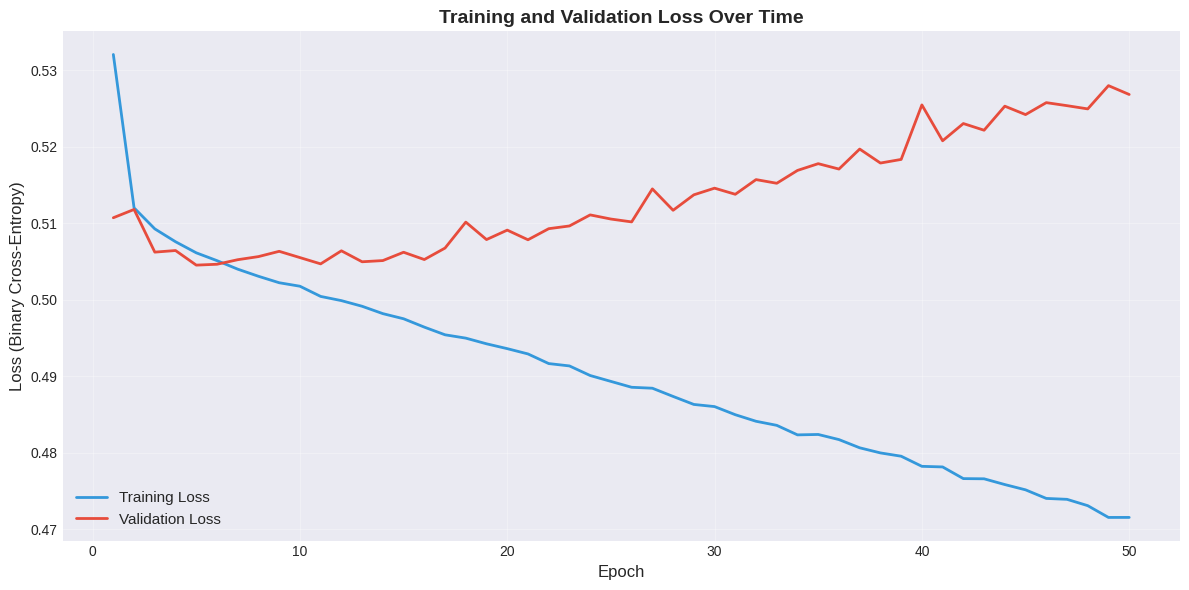


Loss Statistics:
Initial Train Loss: 0.5321
Final Train Loss: 0.4715
Initial Val Loss: 0.5107
Final Val Loss: 0.5268

Loss Reduction:
Training: 11.4% decrease
Validation: -3.2% decrease


In [113]:
# Plot training and validation loss curves

plt.figure(figsize=(12, 6))

epochs_range = range(1, num_epochs + 1)
plt.plot(epochs_range, train_losses, label='Training Loss', linewidth=2, color='#3498db')
plt.plot(epochs_range, val_losses, label='Validation Loss', linewidth=2, color='#e74c3c')

plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (Binary Cross-Entropy)', fontsize=12)
plt.title('Training and Validation Loss Over Time', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print final statistics
print(f"\nLoss Statistics:")
print(f"Initial Train Loss: {train_losses[0]:.4f}")
print(f"Final Train Loss: {train_losses[-1]:.4f}")
print(f"Initial Val Loss: {val_losses[0]:.4f}")
print(f"Final Val Loss: {val_losses[-1]:.4f}")
print(f"\nLoss Reduction:")
print(f"Training: {((train_losses[0] - train_losses[-1]) / train_losses[0] * 100):.1f}% decrease")
print(f"Validation: {((val_losses[0] - val_losses[-1]) / val_losses[0] * 100):.1f}% decrease")

### 4.4 Interpret the loss curves

Understanding loss curves is critical for diagnosing model performance. Here are the patterns to look for:

 Pattern | Loss Behavior | Interpretation | Possible Fixes |
|----------|----------------|----------------|----------------|
| **Healthy Training** | • Both training & validation loss decrease and converge<br>• Small gap between them | Model is learning generalizable patterns | — |
| **Overfitting** | • Training loss keeps decreasing<br>• Validation loss plateaus or increases<br>• Large gap between curves | Model memorizes training data instead of generalizing | Add regularization (dropout, weight decay)<br>Reduce model complexity<br>Collect more data |
| **Underfitting** | • Both losses remain high<br>• Little or no improvement over epochs | Model lacks capacity or training | Increase model complexity<br>Train longer<br>Tune learning rate<br>Improve input features |

Diagnose your model's performance based on loss curves. Answer these questions by analyzing the plot above, either through code or markdown:
 1. What pattern do you see? Does the plot show healthy training, overfitting, or underfitting?
 2. How do you know? _Describe the behavior of the training loss line vs. the validation loss line. (e.g., "Training loss is [decreasing/high] while validation loss is [decreasing/increasing/high]")._
 3. What does this imply? What is the model doing wrong (or right)? _(e.g., "The model is memorizing the training data but failing to generalize...")_

#### Answer
1. The pattern is Overfitting.
2. The validation loss curves begins to increase as the training continues to decrease.
3. This imply the model is memorizing the training data instead of generalizing. 

<details open>
  <summary><h4>Checkpoint – Assess Training Progressing</h4></summary>
  
  Before moving to evaluation, verify that training completed successfully:
  
  - [ ] **Training completed** without errors across all epochs  
  - [ ] **Loss curves analyzed** and any overfitting or underfitting noted  
  - [ ] **Model ready** for comprehensive evaluation on test set  
  
  If training seems problematic (e.g., losses not decreasing), don't worry about it now - that's what optimizations in step 6 will focus on improving!
</details>

---
## Step 5: Evaluate the model

Training loss tells you how well the model fits training data, but comprehensive evaluation requires measuring performance on unseen test data using metrics relevant to your application. 

For medical screening, certain metrics matter more than others. For the baseline model, just check that performance is good-enough (significantly better than random guessing).

### 5.1 Define the evaluation logic

We'll create now a parameterized function that evaluates any model and returns comprehensive metrics.

In [114]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(model: nn.Module,
                   data_loader: DataLoader,
                   device: torch.device,
                   threshold: float = 0.5) -> Dict[str, float]:
    """
    Evaluate a trained model on a dataset and return comprehensive metrics.
    
    Args:
        model: Trained PyTorch model
        data_loader: DataLoader containing the evaluation dataset
        device: Device to run evaluation on (CPU or GPU)
        threshold: Decision threshold for classification (default: 0.5)
    
    Returns:
        Dictionary containing:
            - predictions: numpy array of predicted probabilities
            - true_labels: numpy array of true labels
            - pred_labels: numpy array of predicted binary labels
            - metrics
    """
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            outputs = model(X_batch.to(device))
            all_predictions.append(outputs.squeeze(1).cpu().numpy())
            all_labels.append(y_batch.cpu().numpy())

    predictions = np.concatenate(all_predictions)
    true_labels = np.concatenate(all_labels)
    pred_labels = (predictions >= threshold).astype(int)

    metrics = {
        'accuracy': accuracy_score(true_labels, pred_labels),
        'precision': precision_score(true_labels, pred_labels, zero_division=0),
        'recall': recall_score(true_labels, pred_labels, zero_division=0),
        'f1_score': f1_score(true_labels, pred_labels, zero_division=0),
    }

    results = {
        'predictions': predictions,
        'true_labels': true_labels,
        'pred_labels': pred_labels,
        'metrics': metrics,
    }

    return results

print("Evaluation function created successfully!")

Evaluation function created successfully!


> **Why accuracy isn't enough (even with balanced data):** While accuracy is now meaningful with our 50-50 split (unlike with imbalanced data where it'd be misleading), it still doesn't tell the whole story in medical applications.
> 
> Consider: A model with 75% accuracy could have 90% recall but only 60% precision—great at catching diabetic patients but with many false alarms. Or it could have 90% precision but 60% recall—very accurate when it predicts diabetes, but missing many cases.
> 
> *Bottom line:* Choose metrics that provide a clear view over this trade-off; this is critical in healthcare where different errors have different costs!

### 5.2 Evaluate on test set

Now we'll use our evaluation function to assess the baseline model's performance on the held-out test set. This gives us an unbiased estimate of real-world performance.

In [115]:
# Evaluate the model on the test set using the evaluation function

test_results = evaluate_model(model, test_loader, device)
print(test_results)
for name, value in test_results['metrics'].items():
    print(f"{name:>10}: {value:.4f}")


{'predictions': array([0.9363633 , 0.9263088 , 0.00463193, ..., 0.8056069 , 0.13388668,
       0.95516545], dtype=float32), 'true_labels': array([1, 1, 1, ..., 1, 0, 0]), 'pred_labels': array([1, 1, 0, ..., 1, 0, 1]), 'metrics': {'accuracy': 0.736981555079996, 'precision': 0.7264133106447344, 'recall': 0.7721061093247589, 'f1_score': 0.7485630784218217}}
  accuracy: 0.7370
 precision: 0.7264
    recall: 0.7721
  f1_score: 0.7486


> **Choosing the top metric:** Which is worse for your stakeholders: missing a diabetic patient or triggering an unnecessary test? This determines whether you prioritize recall or precision, and informs threshold selection (we'll use 0.5 as default, but you could adjust it).

### 5.3 Visualize the confusion matrix

The confusion matrix shows exactly where your model succeeds and fails, breaking down predictions into true positives, true negatives, false positives, and false negatives.

True negatives: 3390 | False positives: 1447 | False negatives: 1134 | True positives: 3842


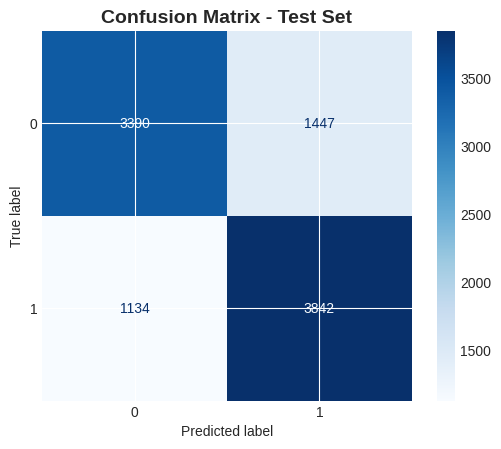

In [116]:
# Create and visualize the confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

true_labels = test_results['true_labels']
pred_labels = test_results['pred_labels']
predictions = test_results['predictions']

cm = confusion_matrix(true_labels, pred_labels)
tn, fp, fn, tp = cm.ravel()
print(f"True negatives: {tn} | False positives: {fp} | False negatives: {fn} | True positives: {tp}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='Blues', colorbar=True)
plt.title('Confusion Matrix - Test Set', fontsize=14, fontweight='bold')
plt.show()

> **Interpreting your confusion matrix** The confusion matrix makes the trade-offs between recall and precision visible. By examining the balance between false positives and false negatives, you can decide which matters more for your real-world goal; for example, catching every diabetic case even if it means more false alarms.

### 5.4 Analyze ROC curve and threshold selection

The ROC (Receiver Operating Characteristic) curve helps you visualize the tradeoff between sensitivity (catching true cases) and specificity (avoiding false alarms) at different decision thresholds.

*Why this matters:*
- The default threshold is 0.5 (predict diabetes if probability > 0.5)
- You might want a different threshold based on your priorities:
  - Lower threshold (e.g., 0.3) → Higher recall, catch more diabetics, but more false alarms
  - Higher threshold (e.g., 0.7) → Higher precision, fewer false alarms, but miss more cases


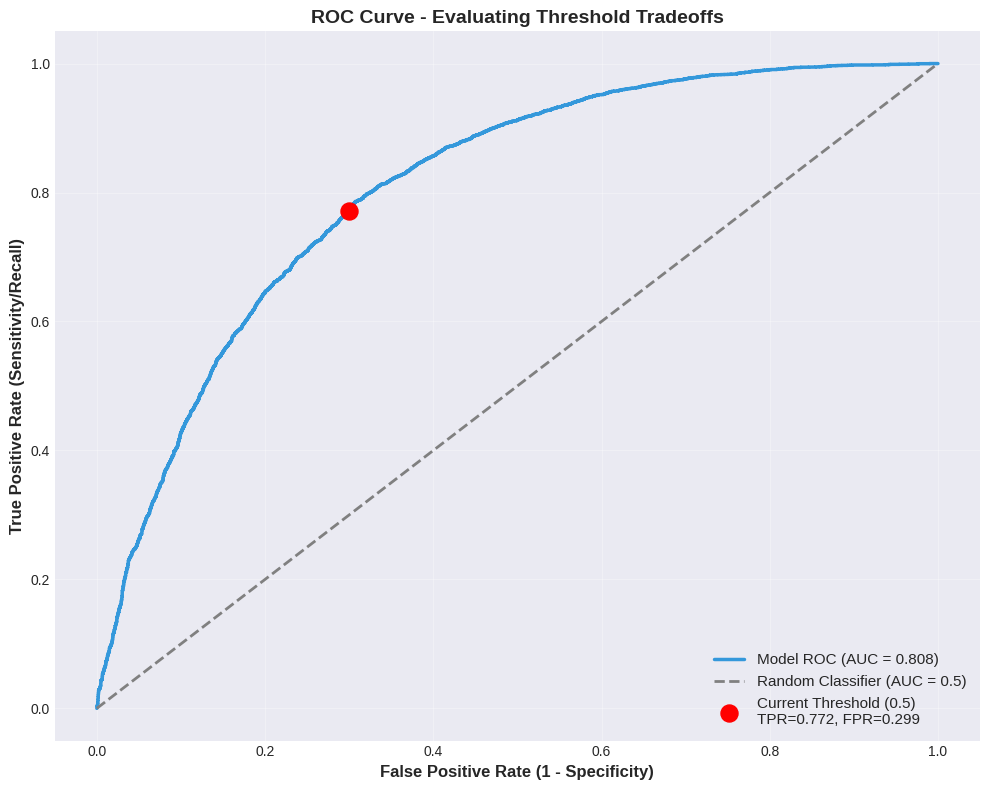


ROC Curve Analysis:
AUC Score: 0.8081
Interpretation:
  - Good discrimination ability

Metrics at each threshold:
  threshold=0.3: accuracy=0.7158, precision=0.6612, recall=0.9013, f1_score=0.7628
  threshold=0.5: accuracy=0.7370, precision=0.7264, recall=0.7721, f1_score=0.7486
  threshold=0.7: accuracy=0.6915, precision=0.7972, recall=0.5253, f1_score=0.6333


In [117]:
# Generate and plot the ROC curve

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(true_labels, predictions)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='#3498db', linewidth=2.5, label=f'Model ROC (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=2, label='Random Classifier (AUC = 0.5)')

# Mark the current operating point (threshold = 0.5)
current_idx = np.argmin(np.abs(thresholds - 0.5))
plt.scatter(fpr[current_idx], tpr[current_idx], color='red', s=150, zorder=5, 
            label=f'Current Threshold (0.5)\nTPR={tpr[current_idx]:.3f}, FPR={fpr[current_idx]:.3f}')

plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity/Recall)', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Evaluating Threshold Tradeoffs', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nROC Curve Analysis:")
print("="*60)
print(f"AUC Score: {roc_auc:.4f}")
print(f"Interpretation:")
if roc_auc >= 0.90:
    print("  - Excellent discrimination ability")
elif roc_auc >= 0.80:
    print("  - Good discrimination ability")
elif roc_auc >= 0.70:
    print("  - Fair discrimination ability")
else:
    print("  - Poor discrimination ability")

print("\nMetrics at each threshold:")
for thr in (0.3, 0.5, 0.7):
    m = evaluate_model(model, test_loader, device, threshold=thr)['metrics']
    print(f"  threshold={thr}: " + ", ".join(f"{k}={v:.4f}" for k, v in m.items()))

> **Understanding the ROC curve**: Each point on the ROC curve represents a different probability threshold for classification. Points in the upper-left corner represent high sensitivity (catching most cases) with low false positive rates (few false alarms). The diagonal line represents random guessing. Depending on your prioritization, you might adjust the threshold as follows:
> - If missing positives is costly, lower the threshold to get the model to label more cases as "positive" → higher true positive rate, higher false positive rate.
> - If false alarms are costly, raise the threshold to get the model to be more strict in labeling cases as "positives" → lower true positive rate, lower false positive rate.

### 5.5 Interpret your results

Beyond raw metrics, it's essential to interpret your model's performance from a healthcare perspective. Let's analyze what these results mean for clinical deployment and patient care.

Reflect on your model's performance from a healthcare perspective. Answer these questions based on your evaluation results:
 1. Which metric is most important for diabetes screening and why? _(Hint: Think about the cost of a False Negative vs. a False Positive)._
 2. Would you recommend using this model in practice? Under what conditions?
 3. What probability threshold would you choose instead of 0.5, and why?

HINT: This model is quite simple since you haven't performed yet hyperparameter tuning, regularization, or feature engineering. Feel free to move forward if you achieve...
#### Answers
1. The recall(High TPR and Low FN) are most important metrics for diabetes screening, the higher the TPR the lower the FN, given that FN is dangerous - it restrict early detection which would have given the patients higher chance to start treatment. We must make sure almost if not all the diabetes patients are found.
2. This model can be used under the condition that the FN candidate be retested.
3. 0.3 Probability threshold increase the recall (TPR) to 90%, catching more daibetes patients reduces the false negative, though it also increase the FPR to 48% - this trade-off is harmless to our customer (patients), and FPR can be dealth with internally.

<details open>
  <summary><h4>Checkpoint – What to Keep in Mind About Your Model Performance </h4></summary>
  
  Before moving forward, record:
  - **Current metrics**: Accuracy ___, Precision ___, Recall ___, F1 ___, ...
  - **Training behavior**: Overfitting (train << val loss)? Underfitting (both high)?
  - **Main issue**: Which needs fixing most—false positives, false negatives, or overall performance?
  
  These observations will guide your improvement strategy in Step 6!
</details>

---
## Step 6: Improve and tune the model

Based on your evaluation results, you will now systematically improve the model. This demonstrates the iterative nature of machine learning: evaluate, diagnose, improve, and repeat. 

You'll experiment with multiple techniques and track results to identify the most impactful improvements.

**Your Goal**: Increase model performance against baseline by >=5% on your top metric.

> **Feel free to change any training parameters: num_epochs, optimizer, ...**

### 6.0 Create experiment tracking system

Before running experiments, let's create a system to automatically track and compare results. This eliminates manual result entry and makes it easy to identify the best-performing configuration.

In [118]:
# Create experiment tracking dictionary
experiment_results = {}

def track_experiment(name: str, 
                     model: nn.Module,
                     train_losses: List[float],
                     val_losses: List[float],
                     test_results: Dict[str, float],
                     notes: str = "") -> None:
    """
    Track experiment results for later comparison.
    
    Args:
        name: Experiment name
        model: Trained model
        train_losses: List of training losses per epoch
        val_losses: List of validation losses per epoch
        test_results: Dictionary from evaluate_model()
        notes: Optional notes about the experiment
    """
   # Keep only numeric metrics so we don't try to tabulate arrays, dicts, etc.
    numeric_metrics = {
        k: float(v) for k, v in test_results.items()
        if isinstance(v, numbers.Number)
    }

    experiment_results[name] = {
        'final_train_loss': float(train_losses[-1]),
        'final_val_loss': float(val_losses[-1]),
        'min_val_loss': float(min(val_losses)),
        'loss_gap': float(abs(train_losses[-1] - val_losses[-1])),
        'metrics': numeric_metrics,           # store all metrics here
        'notes': notes,
        'train_losses': train_losses,         # keep full histories if desired
        'val_losses': val_losses
    }
    print(f"✓ Experiment '{name}' tracked successfully!")


def display_experiment_comparison(sort_by: Optional[str] = "f1",
                                  descending: bool = True) -> Optional[pd.DataFrame]:
    """
    Display a comparison table of all tracked experiments.

    Args:
        sort_by: Metric name to sort by (e.g., 'f1', 'roc_auc', 'accuracy').
                 If None or not present, will fall back to:
                   1) 'roc_auc' if present
                   2) any available metric (alphabetical)
        descending: Sort order for the chosen metric.

    Returns:
        DataFrame with experiment results.
    """
    if not experiment_results:
        print("No experiments tracked yet!")
        return None

    # Collect the union of all metric names across experiments
    all_metric_names = set()
    for res in experiment_results.values():
        all_metric_names.update(res.get('metrics', {}).keys())
    all_metric_names = sorted(all_metric_names)  # stable ordering

    # Determine sort metric
    chosen_sort = None
    if sort_by in all_metric_names:
        chosen_sort = sort_by
    elif all_metric_names:
        chosen_sort = all_metric_names[0]  # fallback to first available
    # If no metrics at all, we’ll sort by final_val_loss

    # Build table rows
    rows = []
    for name, res in experiment_results.items():
        row = {
            'Experiment': name,
            'Val Loss': f"{res['final_val_loss']:.4f}",
            'Loss Gap': f"{res['loss_gap']:.4f}",
        }
        # Add metrics (formatted)
        for m in all_metric_names:
            val = res['metrics'].get(m, None)
            row[m.upper() if m.islower() else m] = (f"{val:.4f}" if isinstance(val, numbers.Number) else "")
        # Also keep raw for sorting
        row['_sort_val'] = (
            res['metrics'].get(chosen_sort)
            if chosen_sort is not None else res['final_val_loss']
        )
        rows.append(row)

    df = pd.DataFrame(rows)

    # Sort
    if chosen_sort is not None:
        df = df.sort_values('_sort_val', ascending=not descending)
    else:
        # No metrics available: sort by Val Loss ascending
        df = df.sort_values('Val Loss', ascending=True, key=lambda s: s.astype(float))

    # Clean up helper column
    df = df.drop(columns=['_sort_val'])

    return df

# Track baseline experiment

def full_metrics(model, test_results):
    """Test metrics from evaluate_model() plus test ROC-AUC and validation F1 (for leakage-free comparison)."""
    metrics = dict(test_results['metrics'])
    metrics['roc_auc'] = roc_auc_score(test_results['true_labels'], test_results['predictions'])
    metrics['val_f1_score'] = evaluate_model(model, val_loader, device)['metrics']['f1_score']
    return metrics

def plot_loss_curves(name, train_losses, val_losses):
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(7, 3.5))
    plt.plot(epochs, train_losses, label='Train loss')
    plt.plot(epochs, val_losses, label='Validation loss')
    plt.xlabel('Epoch'); plt.ylabel('BCE loss'); plt.title(name); plt.legend()
    plt.tight_layout(); plt.show()

def run_experiment(name, model, lr=0.001, notes="", num_epochs=100):
    """Train `model` with Adam, evaluate on val/test, track and plot the loss curves."""
    model = model.to(device)
    n_params = sum(p.numel() for p in model.parameters())
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    _, tr_losses, va_losses = train_model(model, train_loader, val_loader, criterion, optimizer, device,
                                          num_epochs=num_epochs, print_every=50)
    results = evaluate_model(model, test_loader, device)
    track_experiment(name, model, tr_losses, va_losses, full_metrics(model, results),
                     notes=f"{notes} | lr={lr}, params={n_params:,}")
    plot_loss_curves(name, tr_losses, va_losses)
    return model, results

from sklearn.metrics import roc_auc_score

# Track baseline experiment
track_experiment(
    name='Baseline',
    model=model,
    train_losses=train_losses,
    val_losses=val_losses,
    test_results=full_metrics(model, test_results),
    notes='Initial model with default hyperparameters (64-32, no dropout, lr=0.001)'
)

print("\nExperiment tracking system initialized!")
print("Use track_experiment() after training each variation.")
print("Use display_experiment_comparison() to see all results.")

✓ Experiment 'Baseline' tracked successfully!

Experiment tracking system initialized!
Use track_experiment() after training each variation.
Use display_experiment_comparison() to see all results.


> **Running a systematic experiment:** For each experiment, follow this workflow:
> 1. **Define change**: What are you testing? (e.g., dropout=0.3, lr=0.0001)
> 2. **Create model**: Create new model class (if architecture changes) and instantiate with new configuration, e.g., `DiabetesClassifierWithDropout(dropout_prob=0.3).to(device)`
> 3. **Train**: Run training loop, track losses with `train_model()`
> 4. **Evaluate**: Calculate test metrics (accuracy, precision, recall, F1) with `evaluate_model()`
> 5. **Record**: Add results to experiment tracker dictionary with `track_experiment()`
> 6. **Visualize**: Print key experiment metrics for quick analysis
> 
> This systematic approach helps you understand what works and why!

### 6.1 Experiment 1: Add dropout regularization

Dropout randomly deactivates neurons during training, forcing the network to learn robust features that don't rely on specific neurons. This reduces overfitting and improves generalization.

Experiment 1: Training model with Dropout
Epoch [1/100] Train Loss: 0.5370 | Val Loss: 0.5117 | Val Acc: 0.7496
Epoch [50/100] Train Loss: 0.4903 | Val Loss: 0.5089 | Val Acc: 0.7477
Epoch [100/100] Train Loss: 0.4792 | Val Loss: 0.5170 | Val Acc: 0.7479

Training completed!
Final Train Loss: 0.4792
Final Validation Loss: 0.5170
✓ Experiment 'Dropout 0.1' tracked successfully!


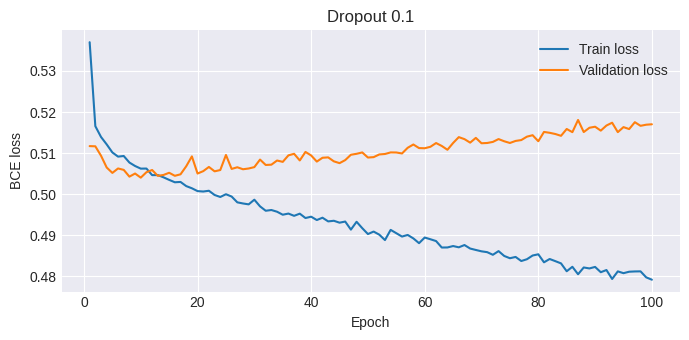

Epoch [1/100] Train Loss: 0.5426 | Val Loss: 0.5129 | Val Acc: 0.7493
Epoch [50/100] Train Loss: 0.4975 | Val Loss: 0.5065 | Val Acc: 0.7488
Epoch [100/100] Train Loss: 0.4916 | Val Loss: 0.5085 | Val Acc: 0.7496

Training completed!
Final Train Loss: 0.4916
Final Validation Loss: 0.5085
✓ Experiment 'Dropout 0.2' tracked successfully!


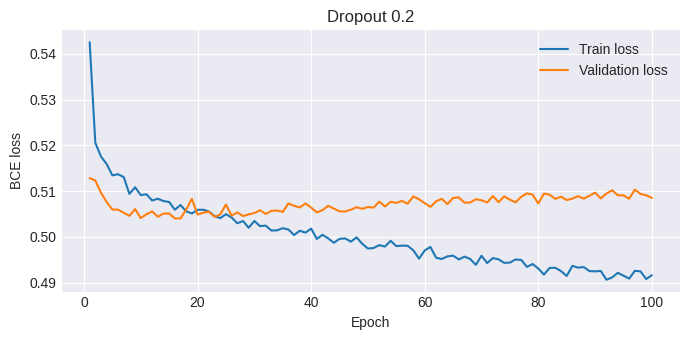

Epoch [1/100] Train Loss: 0.5480 | Val Loss: 0.5132 | Val Acc: 0.7500
Epoch [50/100] Train Loss: 0.5046 | Val Loss: 0.5072 | Val Acc: 0.7498
Epoch [100/100] Train Loss: 0.4999 | Val Loss: 0.5086 | Val Acc: 0.7485

Training completed!
Final Train Loss: 0.4999
Final Validation Loss: 0.5086
✓ Experiment 'Dropout 0.3' tracked successfully!


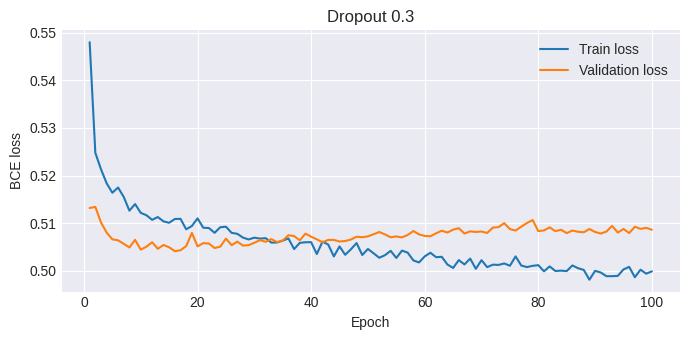

In [119]:
# Create a model with dropout layers and train it

class DiabetesClassifierWithDropout(nn.Module):
    def __init__(self, input_size, hidden_sizes=(64, 32), dropout=0.3):
        super().__init__()
        h1, h2 = hidden_sizes
        self.network = nn.Sequential(
            nn.Linear(input_size, h1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(h2, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.network(x)

print("Experiment 1: Training model with Dropout")
print("="*60)
for rate in (0.1, 0.2, 0.3):
    torch.manual_seed(RANDOM_SEED)
    run_experiment(f"Dropout {rate}", DiabetesClassifierWithDropout(num_features, dropout=rate),
                   notes=f"64-32 with dropout={rate}")

> **How dropout works**: During training, dropout randomly sets a fraction of neuron activations to zero. This prevents the network from relying too heavily on any single neuron and encourages redundancy. During evaluation, dropout is automatically disabled, and all neurons contribute to predictions. This simple technique is remarkably effective at reducing overfitting.

### 6.2 Experiment 2: Tune learning rate

The learning rate controls how large the weight updates are during training. Too high and training becomes unstable; too low and convergence is painfully slow.

Experiment 2: Learning Rate Tuning
Epoch [1/100] Train Loss: 0.5248 | Val Loss: 0.5124 | Val Acc: 0.7484
Epoch [50/100] Train Loss: 0.4748 | Val Loss: 0.5709 | Val Acc: 0.7385
Epoch [100/100] Train Loss: 0.4591 | Val Loss: 0.6172 | Val Acc: 0.7374

Training completed!
Final Train Loss: 0.4591
Final Validation Loss: 0.6172
✓ Experiment 'LR 0.01' tracked successfully!


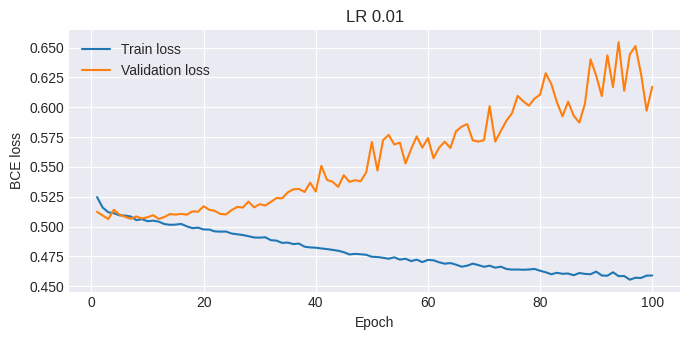

Epoch [1/100] Train Loss: 0.5326 | Val Loss: 0.5110 | Val Acc: 0.7503
Epoch [50/100] Train Loss: 0.4695 | Val Loss: 0.5307 | Val Acc: 0.7373
Epoch [100/100] Train Loss: 0.4460 | Val Loss: 0.5642 | Val Acc: 0.7299

Training completed!
Final Train Loss: 0.4460
Final Validation Loss: 0.5642
✓ Experiment 'LR 0.001' tracked successfully!


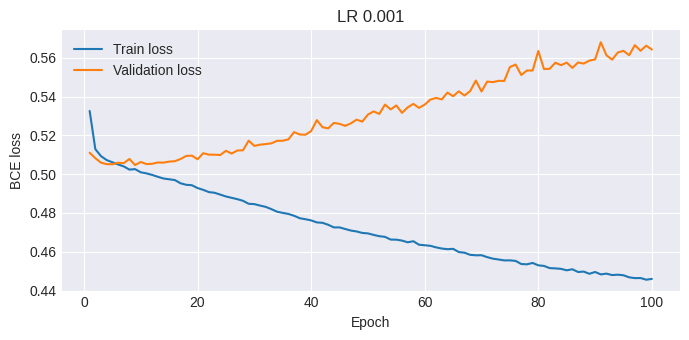

Epoch [1/100] Train Loss: 0.6200 | Val Loss: 0.5521 | Val Acc: 0.7230
Epoch [50/100] Train Loss: 0.4999 | Val Loss: 0.5033 | Val Acc: 0.7504
Epoch [100/100] Train Loss: 0.4940 | Val Loss: 0.5044 | Val Acc: 0.7487

Training completed!
Final Train Loss: 0.4940
Final Validation Loss: 0.5044
✓ Experiment 'LR 0.0001' tracked successfully!


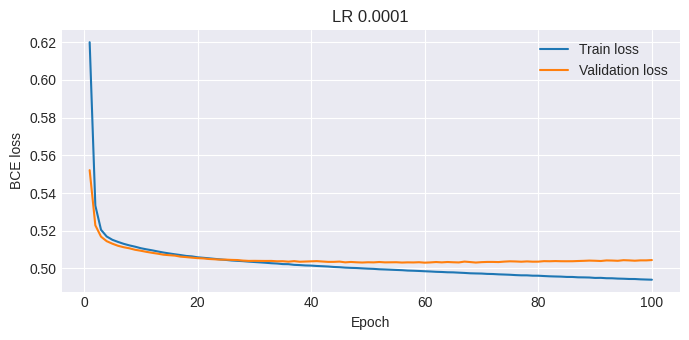

In [120]:
# Experiment with different learning rates

print("Experiment 2: Learning Rate Tuning")
print("="*60)

for lr in (0.01, 0.001, 0.0001):
    torch.manual_seed(RANDOM_SEED)
    run_experiment(f"LR {lr}", DiabetesClassifier(num_features), lr=lr, notes="64-32, no dropout")


> **Choosing a learning rate:** The optimal learning rate depends on your model, dataset, and optimizer. A good starting point is often *1e-3*.
> - If training diverges, lower lr (×0.1).
> - If loss plateaus too early, raise lr (×2–10).
> 
> *Tip*: Adam is generally more forgiving, while SGD benefits from careful tuning.

### 6.3 Experiment 3: Adjust network architecture

Network architecture (depth, width, and layer size) affects model capacity — its ability to learn complex patterns. Too simple and it underfits; too complex and it overfits (especially with limited data).

> **Consider running this experiment multiple times with different architectures**.

Experiment 3: Training with tailored architecture
Epoch [1/100] Train Loss: 0.5366 | Val Loss: 0.5136 | Val Acc: 0.7465
Epoch [50/100] Train Loss: 0.4995 | Val Loss: 0.5071 | Val Acc: 0.7472
Epoch [100/100] Train Loss: 0.4964 | Val Loss: 0.5101 | Val Acc: 0.7443

Training completed!
Final Train Loss: 0.4964
Final Validation Loss: 0.5101
✓ Experiment 'Arch 32' tracked successfully!


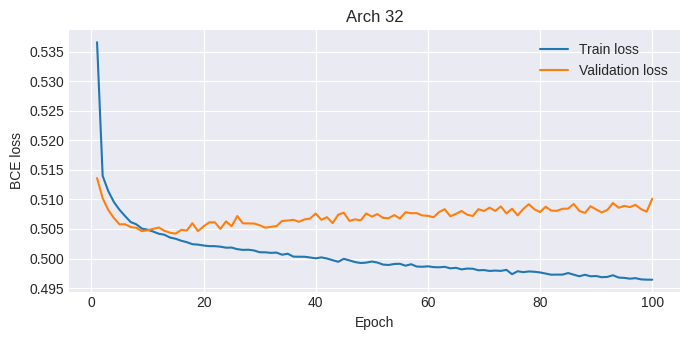

Epoch [1/100] Train Loss: 0.5424 | Val Loss: 0.5144 | Val Acc: 0.7470
Epoch [50/100] Train Loss: 0.4939 | Val Loss: 0.5106 | Val Acc: 0.7459
Epoch [100/100] Train Loss: 0.4857 | Val Loss: 0.5196 | Val Acc: 0.7447

Training completed!
Final Train Loss: 0.4857
Final Validation Loss: 0.5196
✓ Experiment 'Arch 32-16' tracked successfully!


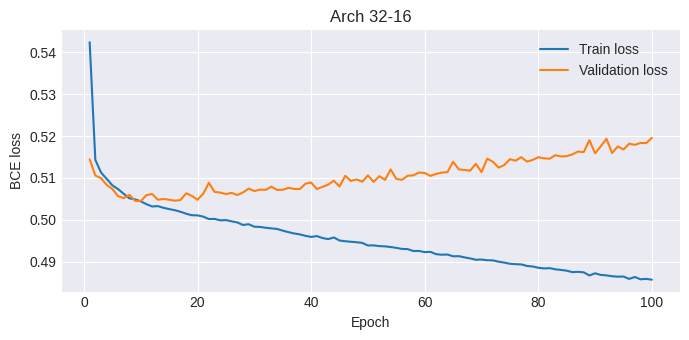

Epoch [1/100] Train Loss: 0.5357 | Val Loss: 0.5119 | Val Acc: 0.7459
Epoch [50/100] Train Loss: 0.4571 | Val Loss: 0.5446 | Val Acc: 0.7373
Epoch [100/100] Train Loss: 0.4208 | Val Loss: 0.6148 | Val Acc: 0.7278

Training completed!
Final Train Loss: 0.4208
Final Validation Loss: 0.6148
✓ Experiment 'Arch 64-32-16' tracked successfully!


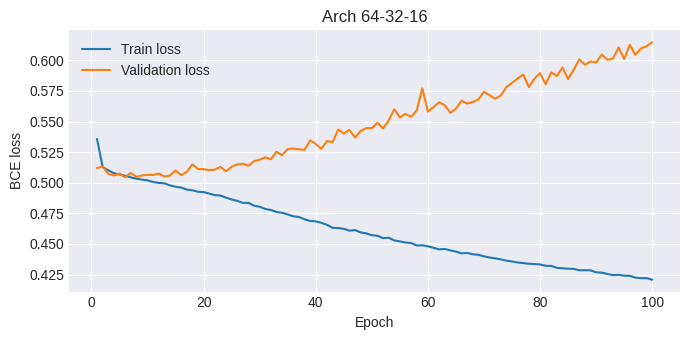

In [121]:
# Define a network architecture that best fits the experienced training behavior and performance

class FlexibleClassifier(nn.Module):
    """MLP with any number of hidden ReLU layers (and optional dropout) for the architecture experiments."""
    def __init__(self, input_size, hidden_sizes, dropout=0.0):
        super().__init__()
        layers, in_features = [], input_size
        for h in hidden_sizes:
            layers += [nn.Linear(in_features, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_features = h
        layers += [nn.Linear(in_features, 1), nn.Sigmoid()]
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

print("Experiment 3: Training with tailored architecture")
print("="*60)

for sizes in [(32,), (32, 16), (64, 32, 16)]:
    torch.manual_seed(RANDOM_SEED)
    run_experiment("Arch " + "-".join(map(str, sizes)), FlexibleClassifier(num_features, sizes),
                   notes=f"hidden layers {sizes}, no dropout")


> **Model capacity tradeoffs**: Larger models (more parameters) can learn more complex patterns but are more prone to overfitting, especially with limited data. For tabular data like ours, simpler architectures often perform just as well or better than deep networks. The key is finding the right balance for your dataset size and complexity.

### 6.4 Compare all experiments

Now let's synthesize findings from all improvement experiments to identify which techniques had the biggest impact on performance.

In [122]:
# Display comprehensive comparison of all experiments
print("Comprehensive Experiment Comparison")
print("="*70)
print("\nAll experiments sorted by F1-Score (best to worst):\n")

comparison_df = display_experiment_comparison()
print(comparison_df.to_string(index=False))

# Identify best configuration
best_experiment = comparison_df.iloc[0]['Experiment']
print(f"\n{'='*70}")
print(f"Best Configuration: {best_experiment}")
print(f"{'='*70}")

print(f"\nKey Insights:")
print("  - Review the 'Loss Gap' column to identify which techniques reduced overfitting")
print("  - Consider the tradeoff between Precision and Recall for your use case")

Comprehensive Experiment Comparison

All experiments sorted by F1-Score (best to worst):

   Experiment Val Loss Loss Gap ACCURACY F1_SCORE PRECISION RECALL ROC_AUC VAL_F1_SCORE
    LR 0.0001   0.5044   0.0104   0.7471   0.7620    0.7286 0.7986  0.8200       0.7637
  Dropout 0.3   0.5086   0.0087   0.7447   0.7660    0.7157 0.8238  0.8178       0.7688
      Arch 32   0.5101   0.0137   0.7440   0.7564    0.7309 0.7838  0.8172       0.7565
  Dropout 0.2   0.5085   0.0169   0.7436   0.7628    0.7185 0.8129  0.8157       0.7683
   Arch 32-16   0.5196   0.0338   0.7412   0.7526    0.7302 0.7763  0.8132       0.7567
  Dropout 0.1   0.5170   0.0378   0.7396   0.7576    0.7176 0.8023  0.8116       0.7643
     Baseline   0.5268   0.0553   0.7370   0.7486    0.7264 0.7721  0.8081       0.7505
      LR 0.01   0.6172   0.1581   0.7356   0.7524    0.7163 0.7924  0.7968       0.7523
     LR 0.001   0.5642   0.1182   0.7257   0.7366    0.7178 0.7564  0.7939       0.7417
Arch 64-32-16   0.6148   0.194


Visualizing Loss Curves for Top 3 Experiments


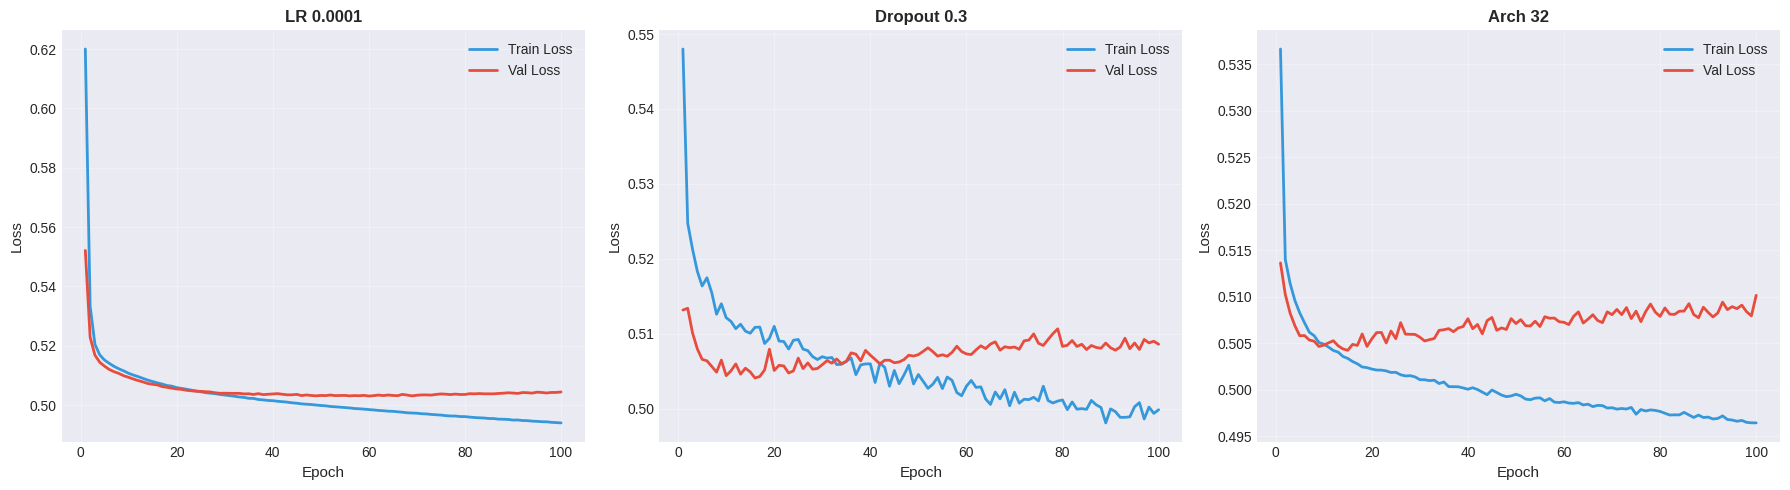

In [123]:
# Visualize loss curves for top 3 experiments
print("\nVisualizing Loss Curves for Top 3 Experiments")
print("="*60)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
top_3_experiments = comparison_df.head(3)['Experiment'].values

for idx, exp_name in enumerate(top_3_experiments):
    exp_data = experiment_results[exp_name]
    epochs = range(1, len(exp_data['train_losses']) + 1)
    
    axes[idx].plot(epochs, exp_data['train_losses'], label='Train Loss', linewidth=2, color='#3498db')
    axes[idx].plot(epochs, exp_data['val_losses'], label='Val Loss', linewidth=2, color='#e74c3c')
    axes[idx].set_xlabel('Epoch', fontsize=11)
    axes[idx].set_ylabel('Loss', fontsize=11)
    axes[idx].set_title(f'{exp_name}', fontsize=12, fontweight='bold')
    axes[idx].legend(fontsize=10)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

> **Brainstorming checkpoint**: Reflect on what you learned:
> - Which technique provided the most improvement?
> - Did any techniques hurt performance?
> - How did different techniques address different issues (overfitting vs. underfitting)?
> - What would you try next if you had more time?

---

### 6.5 Reflect on experiments and brainstorm additional improvements

You've now systematically tested three improvement techniques. It's time to demonstrate your understanding by reflecting on results and proposing what to try next. In real-world ML projects, you'll brainstorm many ideas but only implement the most promising ones due to time and resource constraints.

#### Part A: Reflect on your experimental results

**Analyze your experiment results by answering the following questions. Reference specific metrics, loss curves, and configuration details from your experiments.**

**Questions for reflection:**

1. **Which experiment performed best overall, and why?**

2. **What patterns did you observe across experiments?**
   - Did dropout reduce the train-validation gap? By how much?
   - Which learning rate provided the best balance of convergence speed and stability?
   - Did wider or deeper architectures help? Or did they overfit?

3. **What is your model's biggest remaining weakness?**
   - Is there significant overfitting? (Train-val gap > 0.10)
   - Are false negatives or false positives the bigger problem?
   - Has validation loss plateaued, suggesting you've hit a performance ceiling?

4. **What have you learned about this dataset and problem?**
   - Is the 21-feature set sufficient, or do you suspect important information is missing?
   - Is class imbalance (86% vs 14%) still causing problems despite your experiments?
   - Are there diminishing returns from additional model complexity?

**Answers:**
1. **Dropout 0.3** (64-32 network, lr 0.001) is the best of the dropout, learning-rate and architecture experiments: test F1 0.7660, accuracy 0.7447, recall 0.8238, AUC 0.8178, validation F1 0.7688 (also the highest), and a train-validation gap of only 0.009 (baseline: 0.118).

Best within each family:
- **Dropout:** 0.3 (F1 0.7660), ahead of 0.2 (0.7628) and 0.1 (0.7576).
- **Learning rate:** 0.0001 (F1 0.7620, lowest validation loss of all single experiments, 0.5044).
- **Architecture:** a single hidden layer of 32 units (F1 0.7564, gap 0.014).

Dropout wins because the baseline's main problem was overfitting, and dropout attacks it directly while keeping the highest recall, which matters most for a screening tool. The learning-rate and architecture changes help mainly by overfitting more slowly or having less capacity to overfit.

2. Patterns **Observed accross experiments**  
- **Dropout reduced the train-validation gap:** 0.118 (baseline) to 0.038 (dropout 0.1), 0.017 (0.2) and 0.009 (0.3). That is a reduction of 68%, 86% and 92%. F1 rose from 0.7366 to 0.7576, 0.7628 and 0.7660.
- **Learning rate:** lr 0.0001 was the most stable. Its validation loss is flat at 0.503-0.504 from epoch 50 to 100 (gap 0.010). With lr 0.001 and 0.01 the model converges in a few epochs, but the validation loss then rises (0.564 and 0.617 at epoch 100) while the training loss keeps falling, giving gaps of 0.118 and 0.158. The best validation losses are within 0.003 of each other (0.5031, 0.5047, 0.5064), so the learning rate changed how quickly the model overfits more than how good it can get. Without early stopping, lr 0.0001 gives the best balance of speed and stability over 100 epochs.
- **Architecture:** wider or deeper networks overfit and did not help. Gap and F1: 32 units 0.014 / 0.7564; 32-16 0.034 / 0.7526; 64-32 (baseline) 0.118 / 0.7366; 64-32-16 0.194 / 0.7310. The deepest model had the worst gap, validation loss (0.6148) and F1 of all.

3. Model biggest remaining weakness
- **Overfitting:** only the baseline (0.118), lr 0.01 (0.158) and the 64-32-16 network (0.194) have a gap above 0.10. The tuned models are all below 0.04, so overfitting is no longer the main problem.
- **Error type:** for Dropout 0.3 the confusion matrix is TN 3269, FP 1568, FN 991, TP 3985. False positives are more numerous (1568), but the false negatives matter more clinically: 991 of 3985 diabetic patients (24.86%) are missed. For this same model, lowering the decision threshold to 0.3 (Phase 5 threshold analysis) raised recall to 0.93 at the cost of precision (0.66).
- **Performance ceiling:** yes. Validation loss plateaus between 0.503 and 0.506 and accuracy at about 0.75 for every configuration, and AUC stays at 0.78-0.82 ("fair" to "good"). 90-93% accuracy target is not reachable by tuning this model.

4. What was learned about this dataset
- **Feature set:** the 21 survey indicators appear to be the limiting factor. They contain no laboratory values such as blood glucose or HbA1c, which are the strongest predictors of diabetes. This is an inference from the plateau, not something tested here; a feature-engineering or added-feature experiment would be needed to confirm it.
- **Class imbalance:** not a problem in this dataset. The target is balanced 50/50 (section 3 of the data exploration), not 86%/14%, so no experiment was affected by imbalance, and accuracy is a meaningful metric.
- **Diminishing returns:** yes. More capacity made results worse, and combining the best settings (32 units, dropout 0.3, lr 0.0001) gave F1 0.7654, no better than dropout 0.3 alone (0.7660).



#### Part B: Brainstorm additional improvements

Based on your reflection above, now propose *1-2 specific improvements* you would try next from the list. Choose from the techniques below and provide detailed justification for each.

1. **Class Weights** - Give more importance to the minority class during training
2. **Threshold Tuning** - Adjust the 0.5 decision boundary based on ROC analysis
3. **Early Stopping** - Stop training when validation loss stops improving
4. **Learning Rate Scheduling** - Gradually decrease learning rate during training
5. **Weight Decay (L2 Regularization)** - Add penalty for large weights to reduce overfitting
6. **Data Augmentation** - Oversample minority class or use SMOTE for synthetic examples
7. **Different Activation Functions** - Experiment with LeakyReLU, ELU, ReLU, etc.

> **Important note on feature engineering:** Feature engineering is excluded from this list as it falls outside the scope of neural network optimization techniques. In production, that would be a priority since creating interaction terms _(e.g., BMI × Age, HighBP × HeartDisease)_ or polynomial features could yield 5-10% performance gains, often more than architectural changes.

**For each technique you select (1-2 total), provide a detailed analysis by answering:**

1. **What specific problem from your reflection does your selection address?**
   - Connect directly to weaknesses you identified in Part A
   - Reference specific metrics from your experiment results
   - Example: "Our recall is 0.7345, just barely above target, and we have 387 false negatives"

2. **Why is this technique appropriate for this problem?**
   - Explain the mechanism: how does this technique work?
   - Why would it solve your specific problem?
   - Example: "Class weights force the model to pay more attention to minority class examples during training by increasing their loss contribution"

3. **What results do you expect?**
   - Be specific: which metrics should improve and by roughly how much?
   - What trade-offs might occur? (e.g., precision vs recall)
   - Example: "Recall should increase to 0.75-0.78 because the model will work harder to identify positive cases. Precision may drop slightly from 0.66 to 0.62 due to more false positives, but F1-score should still improve overall"

4. **How would you implement this? (Implementation complexity)**
   - Easy (1-2 line change), Medium (new component), or Hard (major refactor)
   - If Easy or Medium, show the code snippet or describe the modification
   - Example: "Easy - Change loss to: `nn.BCEWithLogitsLoss(pos_weight=torch.tensor([3.0]))`"

### Answers
Here are the two techniques proposed from the list: 
    - **Early Stopping** and
    - **Threshold Tuning**.
They address the two weaknesses found in the reflection:
    - Overfitting during long training runs, and
    - Diabetic patients being missed.
Class weights and SMOTE are not applicable because this dataset is balanced 50/50.
Weight decay, learning-rate scheduling and other activations target the same overfitting problem more indirectly, so they come after early stopping.

#### Technique 1: Early Stopping

**1. Problem addressed.** 
Without a stopping rule, 100 epochs overfit the higher learning rates: the train-validation gap is 0.118 at lr 0.001 and 0.158 at lr 0.01, with final validation losses of 0.564 and 0.617. The same runs reached validation losses of 0.5047 (epoch 9) and 0.5064 (epoch 3) earlier in training. The baseline's F1 of 0.7366 mostly reflects how long it was left running.

**2. Why is Early-Stopping appropriate.** 
The training loop keeps the weights from the last epoch, not the best epoch. Early stopping tracks the validation loss, stops after `patience` epochs without improvement and restores the best weights. This acts as regularization by preventing the model from fitting noise once it stops generalizing. Selection uses the validation loss only, so the test set is not involved.

**3. Expected results.**
- Validation loss near 0.505 and a gap below 0.02 for the baseline and lr 0.01 settings, which overfit most.
- Estimate (not measured): baseline test F1 of about 0.76-0.77, since models with validation loss 0.505-0.509 scored F1 0.763-0.766. Accuracy about 0.745-0.75.
- It will not break the performance ceiling (about 0.75 accuracy, 0.82 AUC), and models that already generalize well (such as dropout 0.3) would change little.
- Trade-off: `patience` is a new hyperparameter, and a value that is too small can stop during a noisy plateau. Training would stop after roughly 15-30 epochs instead of 100.

**4. Implementation Complexity: Medium.**
It changes the Phase 4 `train_model()` function:
```python
best_val, best_state, wait = float('inf'), None, 0
...  # after computing val_loss each epoch
if val_loss < best_val - 1e-4:
    best_val, wait = val_loss, 0
    best_state = {k: v.clone() for k, v in model.state_dict().items()}
else:
    wait += 1
    if wait >= patience:   # e.g. patience=10
        break
...
model.load_state_dict(best_state)
```
The returned loss lists become shorter than `num_epochs`, so the plotting code should use `len(train_losses)`.

### Technique 2: Threshold Tuning

**1. Problem addressed.** For dropout 0.3 the model misses 991 of 3985 diabetic patients (24.8%), with recall 0.8238 and precision 0.7157. For screening, a missed patient costs more than an unnecessary follow-up test. The ROC curve (AUC 0.82) shows room to trade false positives for true positives.

**2. Why it is appropriate.** The model outputs a probability, and 0.5 is only a default. Moving the cut-off changes which patients are flagged without retraining. The Phase 5 threshold analysis already measured this for the same model: at 0.3, recall rose from 0.82 to 0.91 and precision fell from 0.72 to 0.66; at 0.7 recall dropped to 0.58. The threshold must be chosen on the validation set, not the test set, to avoid creating leakage problem.

**3. Expected results.**
- Recall 0.90-0.93 and precision 0.65-0.68. The ends of this range are measured: at threshold 0.3, recall 0.9112, precision 0.6558, F1 0.7647.
- Accuracy falls by about 3 points to roughly 0.72, which moves further from the accuracy target 90-93.
- F1 stays about the same or improves slightly (0.7647 at 0.3 vs 0.7570 at 0.5).
- False negatives fall from 877 to roughly 350, with about 700 additional false positives.

**4. Implementation: Easy.** `evaluate_model` already accepts a `threshold` argument. The cut-off is chosen on validation predictions:
```python
from sklearn.metrics import precision_recall_curve
val = evaluate_model(model, val_loader, device)
prec, rec, thr = precision_recall_curve(val['true_labels'], val['predictions'])
ok = rec[:-1] >= 0.90                      # recall target; set with the clinical team
best_thr = thr[ok][np.argmax(prec[:-1][ok])]
final = evaluate_model(model, test_loader, device, threshold=best_thr)   # test used once
```
The recall target of 0.90 is a clinical decision, not one that can be set from the data alone.


#### Combined Tuning

Experiment 4: Combined Tuning
Epoch [1/100] Train Loss: 0.6268 | Val Loss: 0.5906 | Val Acc: 0.7020
Epoch [50/100] Train Loss: 0.5155 | Val Loss: 0.5082 | Val Acc: 0.7502
Epoch [100/100] Train Loss: 0.5132 | Val Loss: 0.5061 | Val Acc: 0.7503

Training completed!
Final Train Loss: 0.5132
Final Validation Loss: 0.5061
✓ Experiment 'Combined 32 + Dropout 0.3 + LR 0.0001' tracked successfully!


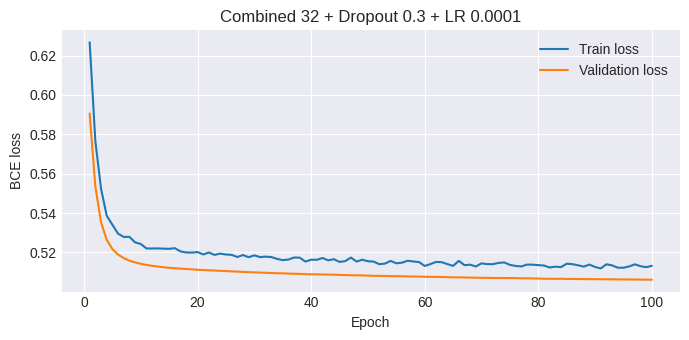

In [77]:
print("Experiment 4: Combined Tuning")
print("=" * 60)
torch.manual_seed(RANDOM_SEED)
combined_model, combined_results = run_experiment(
    "Combined 32 + Dropout 0.3 + LR 0.0001",
    FlexibleClassifier(num_features, (32,), dropout=0.3),
    lr=0.0001,
    notes="hidden layers (32,), dropout=0.3")

In [78]:
comparison_df = display_experiment_comparison(sort_by='f1_score')
print(comparison_df.to_string(index=False))

                           Experiment Val Loss Loss Gap ACCURACY F1_SCORE PRECISION RECALL ROC_AUC VAL_F1_SCORE
                          Dropout 0.3   0.5086   0.0087   0.7447   0.7660    0.7157 0.8238  0.8178       0.7688
Combined 32 + Dropout 0.3 + LR 0.0001   0.5061   0.0070   0.7483   0.7654    0.7256 0.8099  0.8197       0.7668
                          Dropout 0.2   0.5085   0.0169   0.7436   0.7628    0.7185 0.8129  0.8157       0.7683
                            LR 0.0001   0.5044   0.0104   0.7471   0.7620    0.7286 0.7986  0.8200       0.7637
                          Dropout 0.1   0.5170   0.0378   0.7396   0.7576    0.7176 0.8023  0.8116       0.7643
                             Baseline   0.5300   0.0586   0.7392   0.7570    0.7176 0.8008  0.8081       0.7598
                              Arch 32   0.5101   0.0137   0.7440   0.7564    0.7309 0.7838  0.8172       0.7565
                           Arch 32-16   0.5196   0.0338   0.7412   0.7526    0.7302 0.7763  0.8132      

#### Part C: How about combining techniques?

Based on all your experiments, you've seen that different techniques can help solve overfitting but combining them is where most improvements can be unlocked. 

Propose one combined experiment you would run next. Justify your choice and state your expected results.

### Proposed experiment: dropout 0.3 + early stopping + validation-chosen threshold

**Configuration**
- **Model:** the 64-32 network with dropout 0.3, Adam at lr 0.001 (the best single-factor model from Phase 6).
- **Training:** `train_model(..., num_epochs=100, patience=10)`, which stops at the best validation loss and restores those weights.
- **Decision rule:** keep the model's probabilities and pick the threshold on the validation set: the highest precision subject to recall >= 0.90. The test set is evaluated once, with that threshold.

### Why this combination

The earlier combined run (32 units + dropout 0.3 + lr 0.0001) gave no gain: F1 0.7654 against 0.7660 for dropout 0.3 alone. All three of its changes fix the same problem, overfitting, so they did not add up; once dropout closed the train-validation gap to 0.009, the learning rate and the smaller network had nothing left to fix.

The three levers here act on different things:
- **Dropout** regularizes what the network learns.
- **Early stopping** controls when training ends, protecting against the overfitting that 100 epochs bring back.
- **Threshold tuning** sets the decision rule, which no amount of training changes. It is also the only lever aimed at the clinical weakness: the 877 missed diabetic patients (17.6%) at threshold 0.5.

### Expected results

These are estimates, not measurements. The ends of the ranges come from measured runs of the dropout 0.3 model.

| Metric | Dropout 0.3 alone (measured) | Combined (expected) |
|---|---|---|
| Validation loss | 0.5086 | about 0.505 |
| AUC | 0.8178 | 0.815-0.822 (unchanged by the threshold) |
| Recall | 0.8238 | 0.90-0.92 |
| Precision | 0.7157 | 0.66-0.69 |
| False negatives | 877 | about 400-500 |
| Accuracy | 0.7447 | about 0.72-0.73 |
| F1 | 0.7660 | about 0.765-0.77 |

- **Recall and precision** are interpolated between two measured points for this model: threshold 0.5 (recall 0.82, precision 0.72) and threshold 0.3 (recall 0.93, precision 0.66).
- **Early stopping** should barely change the metrics, because dropout 0.3 already has a small gap. Its main benefit is stopping at the best validation loss, probably well before 100 epochs, which reduces training time. The exact stopping epoch is not known in advance.
- **Trade-off:** accuracy falls by about 2-3 points and false positives rise, which moves further from the accuracy target in the mission. The clinical team would need to accept that cost in return for catching more patients.
- **Limit:** this will not unlock large gains. All configurations tried so far fall in a narrow band (validation loss 0.503-0.506, AUC about 0.82), which points to a limit in the data rather than in tuning. The one metric expected to move clearly is recall, and it comes from the threshold.

### How to test it fairly

- Choose the threshold on validation predictions only; the target example 0.90 recall should be a clinical decision.
- Compare against dropout 0.3 alone, adding the components one at a time (dropout, then + early stopping, then + threshold) so each contribution is visible.
- Report false negatives and false positives alongside F1: F1 changes little, while the error counts change a lot.

### Implementation: Medium

`train_model` already supports `patience`; `run_experiment` does not pass it through yet and needs a small change. The threshold step is about five lines (`precision_recall_curve` on the validation set, as sketched in Part B).
```python
def run_experiment(name, model, lr=0.001, notes="", num_epochs=100, patience=None):
    """Train `model` with Adam, evaluate on val/test, track and plot the loss curves."""
    model = model.to(device)
    n_params = sum(p.numel() for p in model.parameters())
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    _, tr_losses, va_losses = train_model(model, train_loader, val_loader, criterion, optimizer, device,
                                          num_epochs=num_epochs, print_every=50, patience=patience)
    results = evaluate_model(model, test_loader, device)
    track_experiment(name, model, tr_losses, va_losses, full_metrics(model, results),
                     notes=f"{notes} | lr={lr}, params={n_params:,}")
    plot_loss_curves(name, tr_losses, va_losses)
    return model, results
```

<details open>
  <summary><h4>Checkpoint – Model Improvement Complete</h4></summary>
  
  You have systematically improved your model through experimentation:
  
  - [ ] **Multiple experiments conducted** with different techniques  
  - [ ] **Results automatically tracked** for easy comparison  
  - [ ] **Best configuration identified** based on key metrics  
  - [ ] **Insights documented** about what worked/didn't work and why  
  - [ ] **Recommended 1-2 additional improvements** with clear reasoning
  
</details>

---
## Conclusion & Next Steps

Congratulations on completing this hands-on deep learning project! You’ve successfully applied neural network fundamentals to a structured data classification task, demonstrating not only technical competence but also an understanding of data preprocessing, model evaluation, and performance optimization.

The techniques and workflows you’ve built here extend far beyond this dataset. The same methods can be applied to credit risk assessment, customer churn prediction, quality control, and more challenges in other structured-data domains. To continue your deep learning journey, explore new datasets, experiment with model architectures, and iterate on performance and interpretability.

#### Want to make this project portfolio-ready?

To showcase this project effectively:

1. Clean your notebook: Clear markdown, add an executive summary, and improve on documentation.
2. Publish on GitHub: Include model results and key visuals.
3. Prepare a short pitch: 2-minute overview of results, impact, and challenges.
4. Highlight strengths: Real-world relevance, handling imbalance, model improvement, metric choice, and deployment readiness.

> **Remember: Machine learning is iterative.** Every model can be improved, every dataset hides deeper insights, and every project sharpens your intuition as a data scientist. Keep experimenting, stay curious, and keep building!